# 最大异常日收益率（ABNRETD）

**行为金融因子 —— 投资者注意力**

$$
\text{ABNRETD} = \max_{t} \left| r_{i,t} - \bar{r}_t \right|
$$

其中：

$$
r_{i,t} \text{ 为股票 } i \text{ 在交易日 } t \text{ 的收益率}
$$$$
\bar{r}_t \text{ 为交易日 } t \text{ 的全市场收益率}
$$$$
m \text{ 为交易日窗口，一般取为月度}
$$

## 因子说明

最大异常日收益率（ABNRETD）是每月内所有交易日中，个股收益率与市场收益率之差的绝对值的最大值，属于**极端日收益类因子**。极端收益（无论是大幅上涨还是大幅下跌）的股票，相比收益平稳的股票更能吸引投资者的关注。因子取值越高，表明该股票在当月曾出现过极端的日收益，投资者的关注度也就越高。**然而，投资者的注意力是有限的，他们更倾向于交易那些引起自己注意的股票**。通常情况下，关注度较高的股票会伴随更多的买入行为。但在 A 股市场中，由于**做多与做空机制不对称**，投资者非理性买入的倾向强于非理性卖出，导致高关注度股票因净买入力量而出现短期价格溢价，这种过度反应往往会在未来引发价格反转。

数据：日度收盘价

In [1]:
# 20日滑动窗口

import numpy as np
import pandas as pd

from rqdatac import all_instruments, get_price, get_trading_dates


def _get_ids(stock_ids=None):
    """默认返回米筐 CS 股票全集。"""
    if stock_ids is not None:
        return list(dict.fromkeys(stock_ids))

    return (
        all_instruments("CS")
        .order_book_id
        .dropna()
        .drop_duplicates()
        .tolist()
    )


def _prepare_dates(start_date, end_date, lookback_days):
    """
    返回：
    target_dates：最终需要输出因子的交易日；
    price_dates：为计算滚动收益而额外向前展开后的价格日期。
    """
    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=start_date - pd.Timedelta(days=max(lookback_days * 3, 90)),
            end_date=end_date,
        )
    )

    target_dates = calendar[
        (calendar >= start_date) & (calendar <= end_date)
    ]

    if len(target_dates) == 0:
        raise ValueError("所选区间内没有交易日。")

    first_loc = calendar.get_loc(target_dates[0])
    last_loc = calendar.get_loc(target_dates[-1])

    if first_loc < lookback_days:
        raise ValueError("历史交易日不足，无法满足滚动窗口。")

    price_dates = calendar[first_loc - lookback_days:last_loc + 1]
    return target_dates, price_dates


def _get_batch_close_volume(batch, price_dates):
    """
    米筐多标的查询不能使用 skip_suspended=True；
    因此下载成交量，并用 volume > 0 排除当日停牌股票。
    """
    raw = get_price(
        order_book_ids=batch,
        start_date=price_dates[0],
        end_date=price_dates[-1],
        frequency="1d",
        fields=["close", "volume"],
        adjust_type="pre",
        skip_suspended=False,
        expect_df=True,
    )

    if raw is None or raw.empty:
        return None, None

    if isinstance(raw.index, pd.MultiIndex):
        close = raw["close"].unstack("order_book_id")
        volume = raw["volume"].unstack("order_book_id")
    else:
        close = raw[["close"]].rename(columns={"close": batch[0]})
        volume = raw[["volume"]].rename(columns={"volume": batch[0]})

    close.index = pd.to_datetime(close.index)
    volume.index = pd.to_datetime(volume.index)

    return (
        close.reindex(index=price_dates, columns=batch),
        volume.reindex(index=price_dates, columns=batch),
    )

# 旧函数
# def _get_returns(close, volume):
#     """仅保留当日实际有成交的股票收益率。"""
#     returns = close.pct_change(fill_method=None).iloc[1:]
#     traded_today = volume.iloc[1:].gt(0)
#     return returns.where(traded_today)

# 新函数，只保留前后两个交易日均正常成交的日收益，避免复牌日后的异常涨幅
def _get_returns(close, volume):
    """只保留前后两个交易日均正常成交的日收益。"""
    returns = close.pct_change(fill_method=None).iloc[1:]

    traded_today = volume.iloc[1:].gt(0)
    traded_yesterday = volume.shift(1).iloc[1:].gt(0)

    valid_price = (
        close.iloc[1:].gt(0)
        & close.shift(1).iloc[1:].gt(0)
    )

    return returns.where(traded_today & traded_yesterday & valid_price)


def _stack_factor(factor_wide, factor_name):
    """日期 × 股票宽表转为 date、order_book_id 两层索引。"""
    panel = factor_wide.stack(dropna=True).rename(factor_name).to_frame()
    panel.index = panel.index.set_names(["date", "order_book_id"])
    return panel

def calculate_abnretd_daily(
    start_date,
    end_date,
    window=20,
    candidate_ids=None,
    market_ids=None,
    batch_size=500,
    min_market_stocks=500,
):
    """
    输出日频、多标的 ABNRETD。

    返回
    ----
    DataFrame
        MultiIndex: date, order_book_id
        Column: ABNRETD
    """
    target_dates, price_dates = _prepare_dates(
        start_date=start_date,
        end_date=end_date,
        lookback_days=window,
    )

    market_ids = _get_ids(market_ids)
    candidate_ids = _get_ids(candidate_ids)

    return_dates = price_dates[1:]

    # 第一遍：计算全市场每日等权收益率 r_bar_t。
    return_sum = pd.Series(0.0, index=return_dates)
    return_count = pd.Series(0, index=return_dates, dtype="int64")

    for start in range(0, len(market_ids), batch_size):
        batch = market_ids[start:start + batch_size]

        close, volume = _get_batch_close_volume(batch, price_dates)
        if close is None:
            continue

        returns = _get_returns(close, volume)

        return_sum += returns.sum(axis=1, skipna=True)
        return_count += returns.notna().sum(axis=1).astype("int64")

    market_returns = (
        return_sum / return_count.replace(0, np.nan)
    ).where(return_count >= min_market_stocks)

    # 第二遍：逐批计算个股的滚动最大异常收益。
    factor_parts = []

    for start in range(0, len(candidate_ids), batch_size):
        batch = candidate_ids[start:start + batch_size]

        close, volume = _get_batch_close_volume(batch, price_dates)
        if close is None:
            continue

        returns = _get_returns(close, volume)

        # 每日异常收益 |r_i,t - r_bar_t|
        abnormal_returns = returns.sub(market_returns, axis=0).abs()

        # 每个交易日均使用过去 window 个交易日滚动计算。
        factor_wide = abnormal_returns.rolling(
            window=window,
            min_periods=window,
        ).max()

        factor_wide = factor_wide.reindex(target_dates)
        factor_parts.append(_stack_factor(factor_wide, "ABNRETD"))

    if not factor_parts:
        return pd.DataFrame(columns=["ABNRETD"])

    return pd.concat(factor_parts).sort_index()

In [2]:
def exclude_recent_listings(abnretd_panel, min_trading_days=60):
    """剔除上市未满指定交易日的股票因子值。

    以股票上市日为第 0 个交易日；当其后的 ``min_trading_days`` 个交易日均已
    过去，才保留因子。例如 ``min_trading_days=60`` 时，上市后的第 61 个交易日
    起才允许使用 ABNRETD。该规则可避免新股上市初期的无涨跌幅限制波动主导排序。

    本函数只过滤最终因子面板；因此可以直接接在
    ``calculate_abnretd_daily(...)`` 后使用。
    """
    if min_trading_days < 0:
        raise ValueError("min_trading_days 不能为负数。")
    if not isinstance(abnretd_panel.index, pd.MultiIndex) or abnretd_panel.index.nlevels != 2:
        raise ValueError("索引必须为两层 MultiIndex：(date, order_book_id)。")

    # 延迟导入，使单纯的数据检查不依赖已初始化的 rqdatac。
    from rqdatac import all_instruments, get_trading_dates

    panel = abnretd_panel.copy()
    panel.index = panel.index.set_names(["date", "order_book_id"])
    signal_dates = pd.DatetimeIndex(panel.index.get_level_values("date"))
    stock_ids = pd.Index(panel.index.get_level_values("order_book_id").unique())

    instruments_df = all_instruments("CS").set_index("order_book_id")
    listed_dates = pd.to_datetime(
        instruments_df["listed_date"].reindex(stock_ids), errors="coerce"
    )
    if listed_dates.isna().any():
        missing_ids = listed_dates[listed_dates.isna()].index.tolist()[:10]
        raise ValueError("以下股票缺少 listed_date：{}".format(missing_ids))

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=listed_dates.min(),
            end_date=signal_dates.max(),
        )
    )
    listing_locs = calendar.searchsorted(listed_dates.to_numpy(), side="left")
    eligible_locs = listing_locs + min_trading_days

    eligible_from_values = np.full(
        len(stock_ids), np.datetime64("NaT"), dtype="datetime64[ns]"
    )
    within_calendar = eligible_locs < len(calendar)
    eligible_from_values[within_calendar] = calendar.to_numpy()[eligible_locs[within_calendar]]
    eligible_from = pd.Series(pd.to_datetime(eligible_from_values), index=stock_ids)

    row_ids = panel.index.get_level_values("order_book_id")
    row_eligible_from = eligible_from.reindex(row_ids).to_numpy()
    keep = signal_dates.to_numpy() >= row_eligible_from
    return panel.loc[keep].sort_index()

In [3]:
abnretd_panel = calculate_abnretd_daily(
    start_date="2020-01-01",
    end_date="2025-12-31",
    window=20,
)

# 上市后的第 61 个交易日起才保留因子
abnretd_panel = exclude_recent_listings(
    abnretd_panel,
    min_trading_days=60,
)

abnretd_panel.head()

ABNRETD
date       order_book_id          
2020-01-02 000001.XSHE    0.023971
           000002.XSHE    0.036420
           000004.XSHE    0.070491
           000005.XSHE    0.016281
           000006.XSHE    0.020352

In [4]:
# 行：交易日；列：order_book_id；值：ABNRETD
abnretd_panel_df = (
    abnretd_panel["ABNRETD"]
    .unstack("order_book_id")
    .sort_index()
)

abnretd_panel_df.index = pd.to_datetime(abnretd_panel_df.index)
abnretd_panel_df.columns.name = "order_book_id"

In [5]:
abnretd_panel_df

order_book_id,000001.XSHE,000002.XSHE,000004.XSHE,000005.XSHE,000006.XSHE,000007.XSHE,000008.XSHE,000009.XSHE,000010.XSHE,000011.XSHE,...,603406.XSHG,301632.XSHE,603370.XSHG,301575.XSHE,603418.XSHG,301584.XSHE,301656.XSHE,301668.XSHE,001285.XSHE,301563.XSHE
date,,,,,,,,,,,,,,,,,,,,,
2020-01-02,0.023971,0.036420,0.070491,0.016281,0.020352,0.096497,0.042770,0.096173,0.041429,0.031079,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,0.023971,0.036420,0.070491,0.016281,0.020352,0.096497,0.042770,0.096173,0.020716,0.031079,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-06,0.023971,0.036420,0.070491,0.016281,0.020352,0.096497,0.042770,0.096173,0.016315,0.031079,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-07,0.023971,0.036420,0.070491,0.016281,0.020352,0.037666,0.018859,0.096173,0.018540,0.031079,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-08,0.023971,0.036420,0.070491,0.016281,0.020352,0.037666,0.018859,0.096173,0.018540,0.031079,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-25,0.020615,0.099823,0.049326,NaN,0.058848,0.102615,0.022967,0.022155,0.046222,0.030362,...,0.032863,0.025218,0.025088,0.068561,0.032784,NaN,NaN,NaN,NaN,NaN
2025-12-26,0.019766,0.099823,0.049326,NaN,0.058848,0.102615,0.022967,0.022155,0.046222,0.030362,...,0.032863,0.022870,0.025088,0.068561,0.032784,0.041987,0.032236,NaN,NaN,NaN
2025-12-29,0.019766,0.099823,0.049326,NaN,0.036759,0.102615,0.022967,0.022155,0.046222,0.019199,...,0.032863,0.022870,0.025088,0.068561,0.032784,0.041987,0.032236,0.040753,NaN,NaN


In [6]:
from rqfactor.notebook import factor_analysis

result_abnretd = factor_analysis(
    f=abnretd_panel_df,
    period=1,
    shift=1,
    rank_ic=True,
    quantile=5,
    ascending=True,
    winzorization="mad",
    normalization=False,
    neutralization="none",   # 先关闭：这是日频测试最常见的慢点
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)

# 中性化版本
# result_abnretd_industry = factor_analysis(
#     f=abnretd_panel_df,
#     period=1,
#     shift=1,
#     rank_ic=True,
#     quantile=5,
#     ascending=True,
#     winzorization="mad",
#     normalization=True,
#     neutralization="industry",
#     include_st=False,
#     include_new=False,
#     benchmark="000906.XSHG",
# )

result_abnretd.show()

Loading BokehJS ...

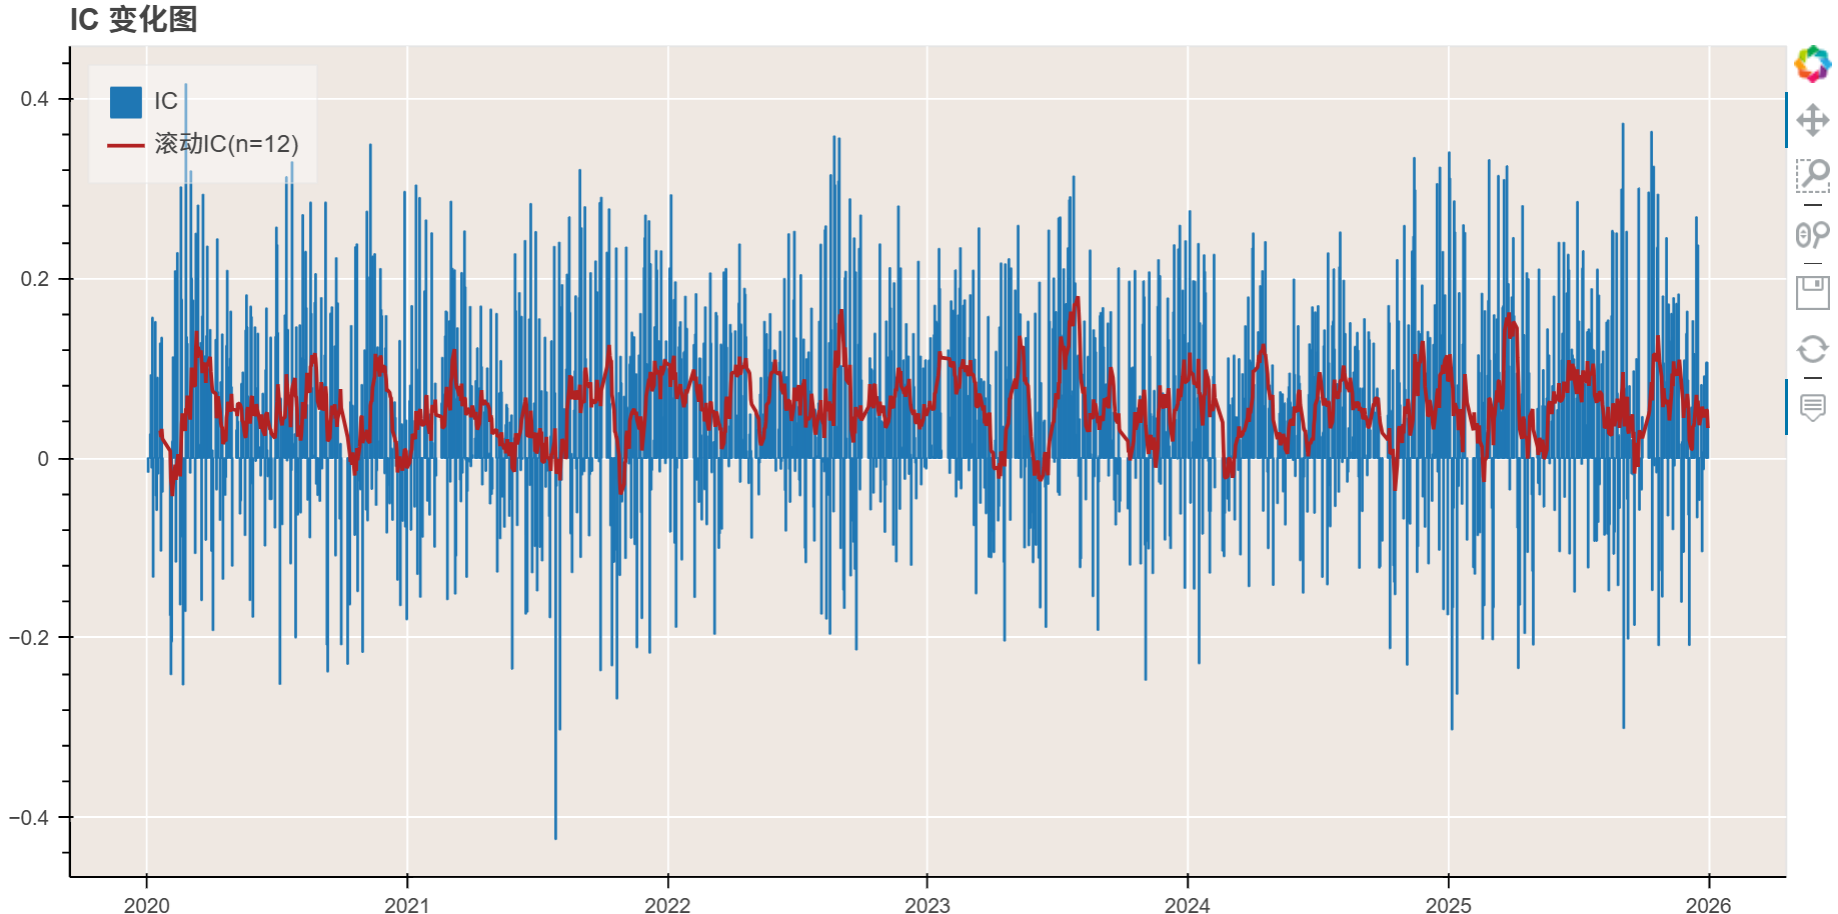

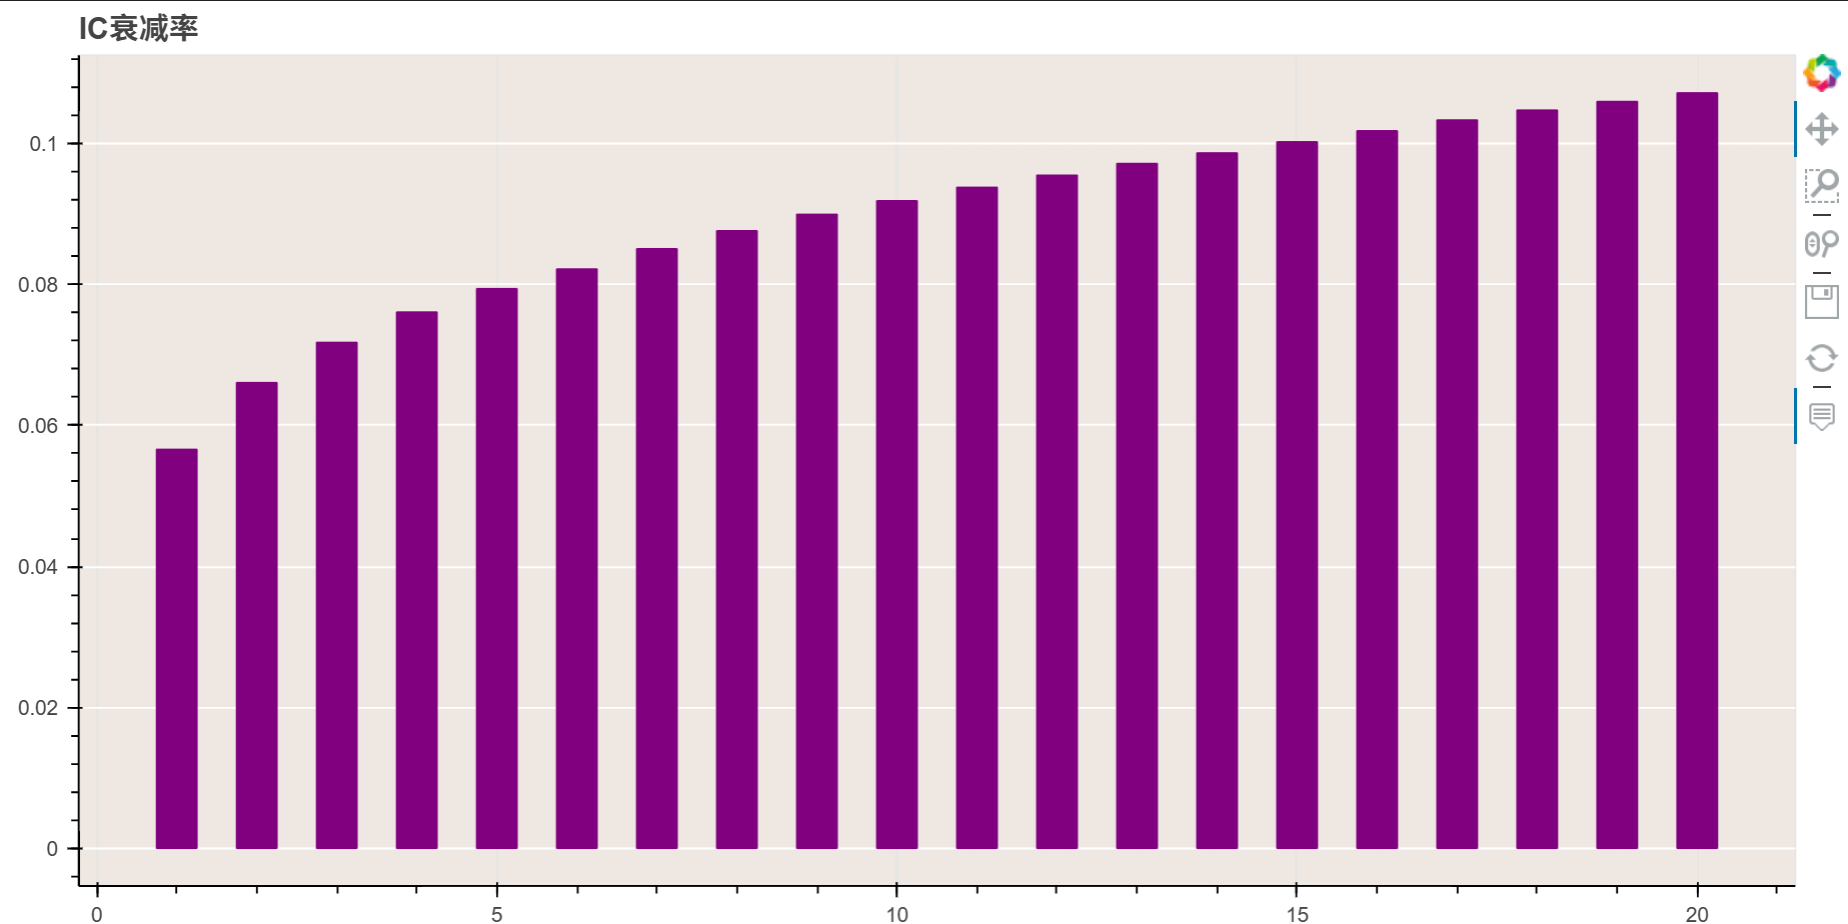

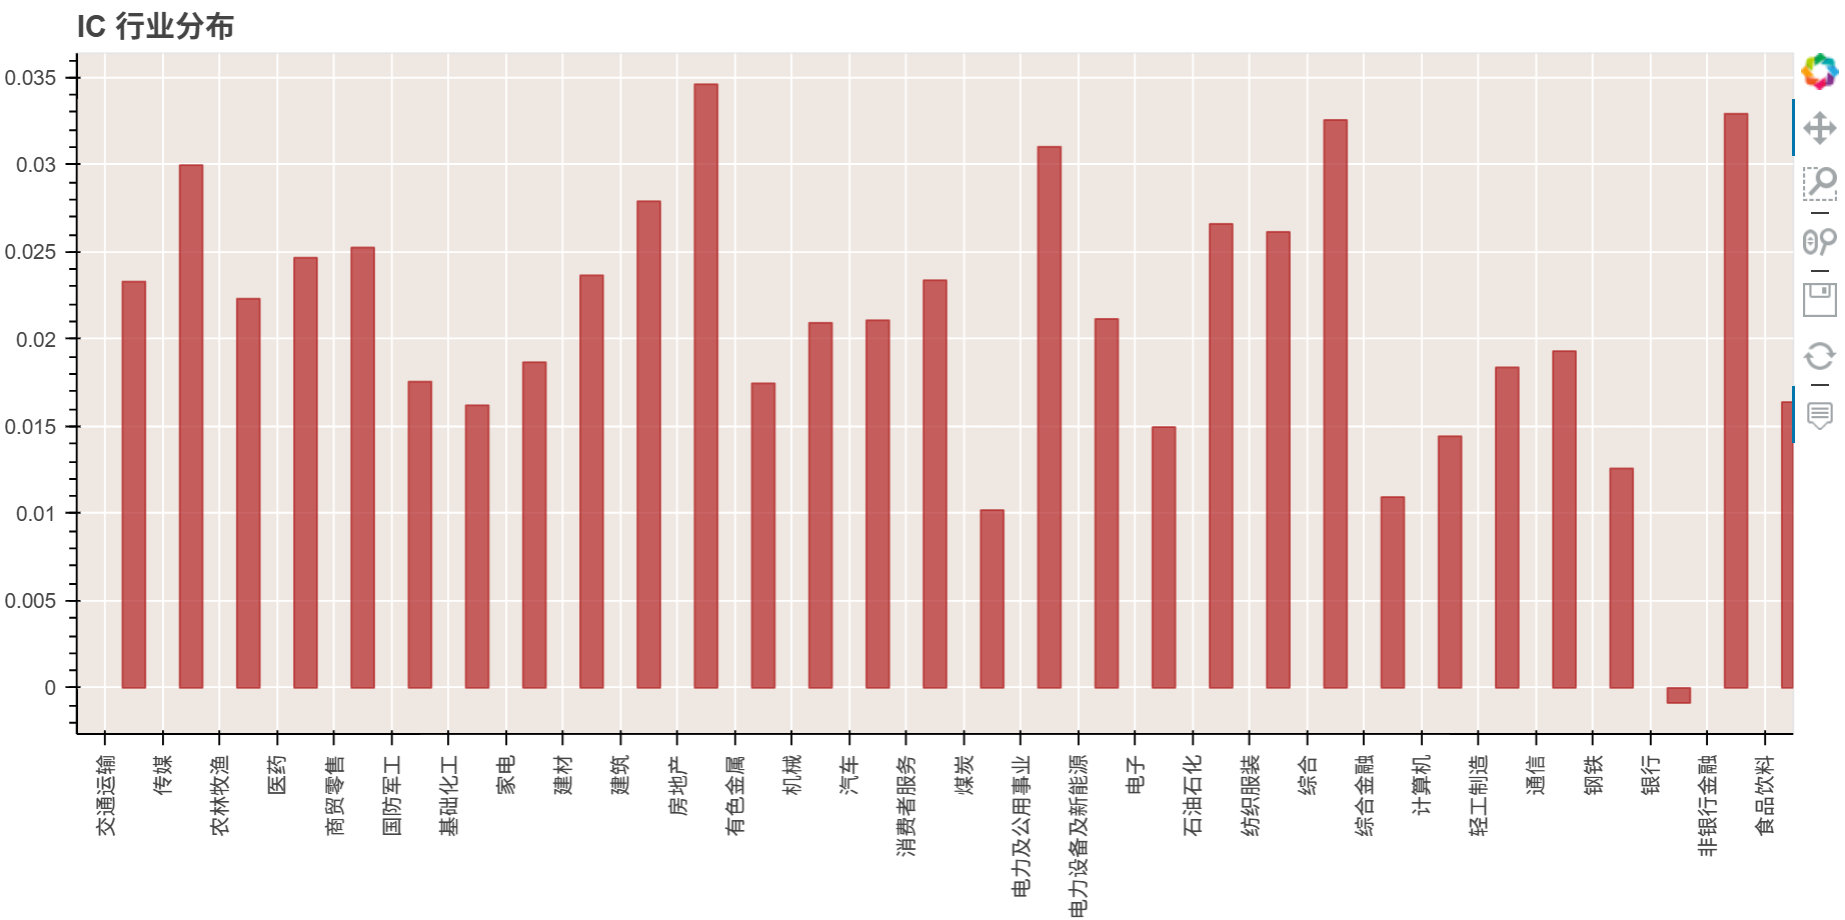

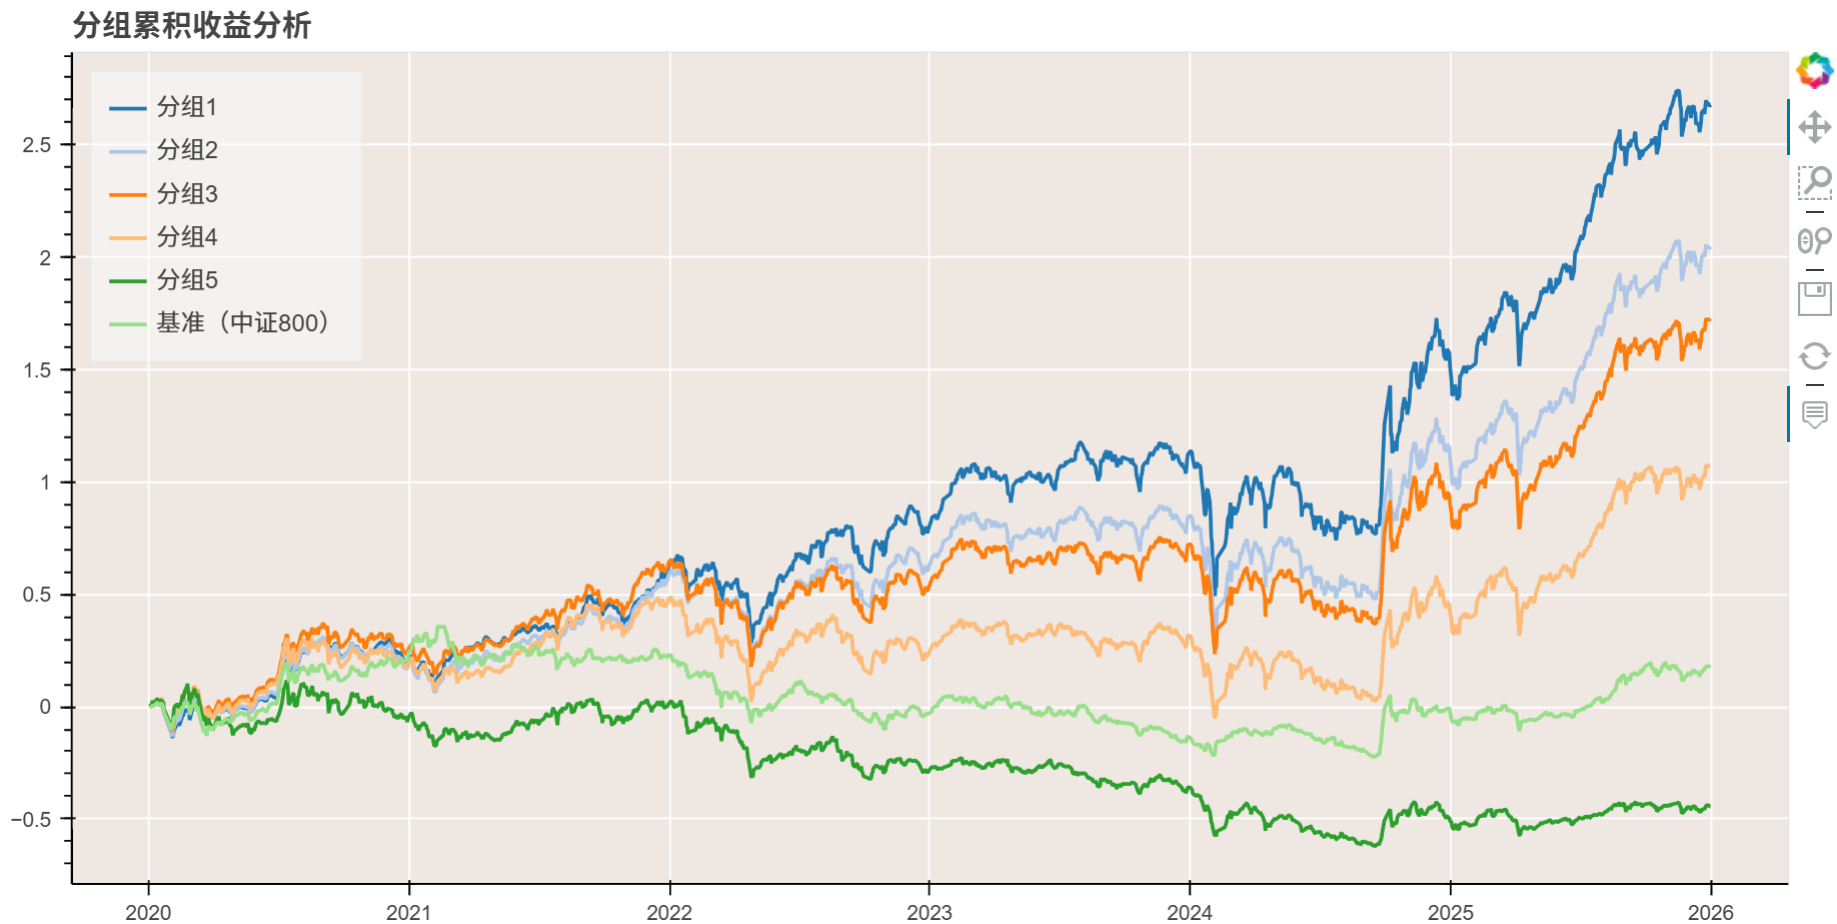

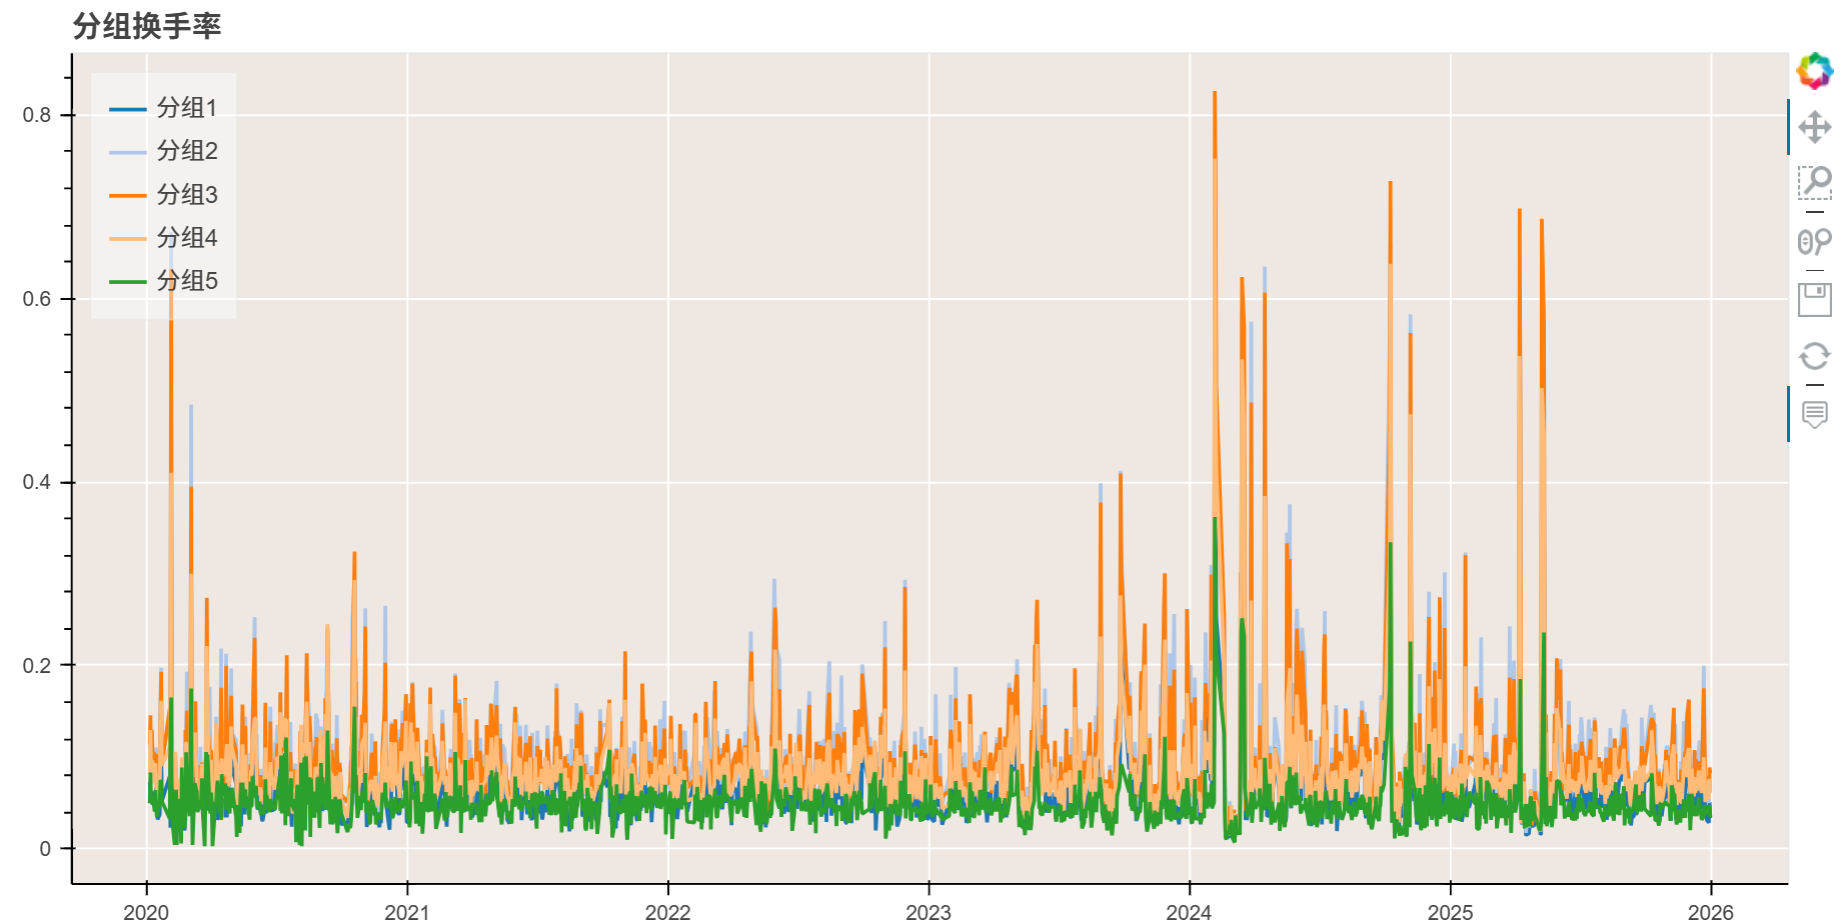

In [7]:
result_abnretd.ic_summary

{'mean': 0.05657477849415061,
 'std': 0.1227894041656794,
 'positive': 982,
 'negative': 472,
 'significance': 0.7916093535075653,
 'sig_positive': 0.5701513067400276,
 'sig_negative': 0.22145804676753783,
 't_stat': 17.56888392588331,
 'p_value': 8.319675666720294e-63,
 'skew': -0.13516019912347887,
 'kurtosis': -0.18057434457988375,
 'ir': 0.4607464209030155}

In [8]:
result_abnretd.ic

2020-01-03   -0.015626
2020-01-06    0.026525
2020-01-07    0.092423
2020-01-08   -0.010686
2020-01-09    0.156386
                ...   
2025-12-25   -0.012560
2025-12-26    0.091033
2025-12-29    0.106241
2025-12-30    0.106248
2025-12-31    0.034516
Length: 1454, dtype: float64

In [9]:
result_abnretd.quantile_factor_returns

,2020-01-03,2020-01-06,2020-01-07,2020-01-08,2020-01-09,2020-01-10,2020-01-13,2020-01-14,2020-01-15,2020-01-16,...,2025-12-18,2025-12-19,2025-12-22,2025-12-23,2025-12-24,2025-12-25,2025-12-26,2025-12-29,2025-12-30,2025-12-31
q0,0.0,0.005918,0.018250,0.003334,0.016827,0.015334,0.020959,0.023660,0.015623,0.008030,...,2.599285,2.644760,2.657497,2.637646,2.671771,2.699781,2.688442,2.682753,2.671540,2.678716
q1,0.0,0.005745,0.018960,0.005476,0.020135,0.019781,0.027847,0.028693,0.022130,0.015295,...,1.963332,2.003724,2.013867,2.001037,2.031287,2.057052,2.047852,2.045031,2.038629,2.047220
q2,0.0,0.007325,0.019943,0.006223,0.023264,0.021757,0.033073,0.032896,0.029750,0.027564,...,1.625752,1.667389,1.683636,1.670223,1.699793,1.728465,1.723945,1.723382,1.722134,1.727051
q3,0.0,0.007337,0.020697,0.006024,0.023098,0.021341,0.034785,0.032057,0.031514,0.028720,...,0.982181,1.010291,1.029942,1.020478,1.050289,1.073983,1.073411,1.070681,1.072005,1.072766
q4,0.0,0.010807,0.026390,0.012388,0.026598,0.018857,0.032963,0.032161,0.026250,0.024499,...,-0.468827,-0.459971,-0.455262,-0.458420,-0.448666,-0.442212,-0.438610,-0.440061,-0.443699,-0.443365


In [10]:
result_abnretd.quantile_turnover

index,2020-01-06,2020-01-07,2020-01-08,2020-01-09,2020-01-10,2020-01-13,2020-01-14,2020-01-15,2020-01-16,2020-01-17,...,2025-12-18,2025-12-19,2025-12-22,2025-12-23,2025-12-24,2025-12-25,2025-12-26,2025-12-29,2025-12-30,2025-12-31
q0,0.072674,0.058224,0.055233,0.062500,0.047965,0.061047,0.046444,0.066763,0.050798,0.031930,...,0.049746,0.043699,0.123984,0.079349,0.034588,0.038657,0.031536,0.028484,0.050865,0.033537
q1,0.116448,0.109170,0.097525,0.128093,0.085881,0.104651,0.087209,0.110305,0.075581,0.052326,...,0.088415,0.066057,0.199390,0.118006,0.068159,0.063136,0.062118,0.049898,0.086470,0.061038
q2,0.113537,0.145560,0.085881,0.129549,0.104651,0.103348,0.095930,0.103198,0.059593,0.072569,...,0.080285,0.077236,0.174975,0.113937,0.063136,0.079349,0.065107,0.066191,0.088595,0.082401
q3,0.081514,0.129549,0.077147,0.096070,0.091703,0.071221,0.093023,0.074020,0.052326,0.068314,...,0.065041,0.060976,0.099695,0.080366,0.050865,0.074338,0.059063,0.053971,0.076297,0.069176
q4,0.049491,0.082969,0.050946,0.056686,0.056686,0.040698,0.063953,0.044993,0.034884,0.037736,...,0.037602,0.031504,0.035605,0.047813,0.036623,0.046796,0.045778,0.042726,0.047813,0.034588


In [11]:
ic = result_abnretd.ic.dropna()

print("IC 均值：", ic.mean())
print("IC 标准差：", ic.std())
print("ICIR：", ic.mean() / ic.std())
print("正 IC 比例：", (ic > 0).mean())
print("负 IC 比例：", (ic < 0).mean())

IC 均值： 0.05657477849415061
IC 标准差： 0.1227894041656794
ICIR： 0.4607464209030155
正 IC 比例： 0.6753782668500687
负 IC 比例： 0.3246217331499312


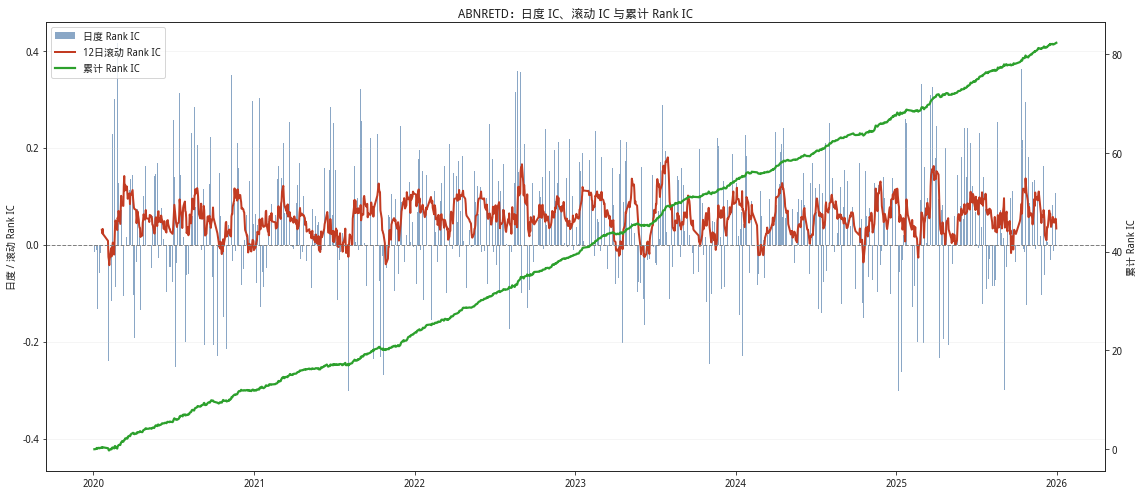

In [12]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result_abnretd.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="日度 Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}日滚动 Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("日度 / 滚动 Rank IC")
ax1.set_title("ABNRETD：日度 IC、滚动 IC 与累计 Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="累计 Rank IC",
)

ax2.set_ylabel("累计 Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["日度 Rank IC", f"{rolling_window}日滚动 Rank IC", "累计 Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()

这不是“有一点效果”，而是一个在 2020–2025 全样本上非常强、且分层关系极清晰的结果。严格说区间覆盖了 6 个自然年、1,454 个交易日。

| 指标 | 结果 |
|---|---:|
| 平均 IC | 0.0566 |
| IC 标准差 | 0.1228 |
| 日频 ICIR | 0.4607 |
| 正 IC 占比 | 67.5% |
| t 值 | 17.57 |
| p 值 | \(8.3 \times 10^{-63}\) |

分层累计收益更有说服力：从分组 1 到分组 5 几乎严格递减。

| 分组 | 样本期累计收益 |
|---|---:|
| 分组 1 / q0 | 267.9% |
| 分组 2 / q1 | 204.7% |
| 分组 3 / q2 | 172.7% |
| 分组 4 / q3 | 107.3% |
| 分组 5 / q4 | -44.3% |

也就是说，最优组与最差组在期末累计收益上相差约 312 个百分点。这是非常漂亮的单因子分层曲线，且并非仅由 2020 年贡献：从图形看，2021–2025 的组间排序基本持续存在，2024–2025 还明显扩大。

IC 衰减图从 1 日约 `0.056` 上升到 20 日约 `0.108`，说明信号在随后数日并未迅速失效；它的经济影响会持续累积。不过，不能直接凭 20 日 IC 更高就改成 20 日调仓——长周期累计收益的 IC 天然会更高一些。你当前的日频 IC 显著性和样本量最充分，仍是最可靠的基础结论。

行业图也很好：绝大部分行业为正，且没有只依赖一个行业。房地产、电力设备及新能源、综合、非银金融等较强；银行略弱甚至接近零。这表明它不是一个仅在单一行业有效的窄信号，但仍需要做行业和风格中性化来确认独立性。

换手率方面，日常大多约 4%–10%，中间组和若干日期会出现很高尖峰。好消息是首尾组通常不是换手最高的组；坏消息是这个收益尚未扣除手续费、滑点、涨跌停和停牌造成的无法成交。

有一个方向问题必须纠正：我前面把手工 `qcut` 得到的 `0–4` 标签，直接等同于米筐输出的 `q0–q4`，这并不严谨。现在唯一安全的结论是：

> 在你这次 `factor_analysis` 的排序设定下，分组 1 是明显的优组，分组 5 是明显的劣组。

由于平均 Rank IC 为正，若米筐没有对 IC 按 `ascending` 自动翻向，那么高 ABNRETD 对应更高未来收益；若分组 1 又是低 ABNRETD，则 IC 与分组方向会矛盾。实际进入策略前，应把方向做一次明确核验，而不是根据组名猜测。

下一步最值得做的不是继续扩样本，而是做两项“验真”：

```python
# 1. 行业 + 风格中性化版本
# 目标：排除市值、波动率、流动性、行业暴露后，信号是否仍成立。
```

```python
# 2. 使用 RQAlpha Plus 做可交易回测
# T 日收盘形成信号；
# T+1 开盘执行；
# 加入佣金、滑点、涨跌停、停牌和持仓数量限制；
# 输出净值、夏普、最大回撤、年化收益、交易成本后超额。
```

在此之前，这个结果应描述为：**ABNRETD 是一个跨多年、日频 IC 稳定、分层单调性极强的候选因子；但尚未证明是可交易的独立 Alpha。**

In [13]:
from ABNRETD_数据检查 import check_abnretd_output

summary, by_date, suspicious = check_abnretd_output(
    abnretd_panel,
    extreme_threshold=0.30,  # 超过 30% 列为待核查，不自动判错
)

print(summary.to_string(index=False))
print(by_date.tail())
print(suspicious.head(20))

# 它只检查：
# - 是否有重复的 date-stock、缺失值、inf、负值；
# - 总体均值、标准差、1%/99% 分位数、最大最小值；
# - 每日股票覆盖数和每日横截面分布；
# - 大于 30% 的异常值清单，供核对复权、停复牌和错误价格。
# 合理性上，ABNRETD 应始终大于等于 0；0.05 表示过去窗口内最大异常日收益为 5%。超过 30% 不一定错误，但建议逐个检查。该轻量脚本已用合成数据验证。

# 旧函数结果
#                  指标            数值                        判断
#                 观测数  6.760655e+06                          
#                交易日数  1.455000e+03                  样本期交易日数量
#                 股票数  5.374000e+03                 样本期覆盖股票数量
#       重复 date-stock  0.000000e+00                      应为 0
#                 缺失值  0.000000e+00              最终因子面板通常应为 0
#  非有限值（inf/-inf/NaN）  0.000000e+00                      应为 0
#                  负值  0.000000e+00     应为 0：ABNRETD 是绝对值的最大值
#                零值占比  0.000000e+00  通常接近 0；大量为 0 需核对收益率或市场收益
#                  均值  5.864736e-02          日收益率单位，0.05 即 5%
#                 标准差  3.656208e-02              越大表示横截面离散度越高
#                 最小值  4.696529e-03                   应大于等于 0
#               1%分位数  1.377449e-02                    检查低端分布
#                 中位数  4.895752e-02            典型股票的月内最大异常日收益
#              99%分位数  1.957581e-01                    检查高端分布
#                 最大值  4.877768e+00                 建议核对特别大的值
#          > 30% 的观测数  1.540000e+02          仅为人工复核阈值，不自动表示错误
#              股票数        均值       标准差       最小值       中位数       最大值       P01  \
# date                                                                           
# 2025-12-25  5102  0.052410  0.036897  0.009051  0.040355  0.216634  0.012246   
# 2025-12-26  5103  0.052616  0.037203  0.008990  0.040415  0.216634  0.012242   
# 2025-12-29  5103  0.052799  0.037513  0.008990  0.040499  0.216634  0.012383   
# 2025-12-30  5105  0.053083  0.037442  0.008990  0.040815  0.216634  0.012110   
# 2025-12-31  5105  0.053156  0.037548  0.009051  0.041156  0.216634  0.012112   

#                  P99  极端值数量  
# date                         
# 2025-12-25  0.194681      0  
# 2025-12-26  0.197331      0  
# 2025-12-29  0.197964      0  
# 2025-12-30  0.197677      0  
# 2025-12-31  0.197961      0  
#                            ABNRETD
# date       order_book_id          
# 2022-09-19 000670.XSHE    4.877768
# 2021-01-13 000995.XSHE    3.161211
# 2021-09-06 000792.XSHE    3.050057
# 2024-10-31 301551.XSHE    2.463692
# 2024-11-01 301551.XSHE    2.463692
# 2020-02-27 688026.XSHG    1.173868
# 2020-02-28 688026.XSHG    1.173868
# 2021-03-04 300939.XSHE    1.004448
# 2021-03-05 300939.XSHE    1.004448
# 2021-03-04 300937.XSHE    0.910111
# 2021-03-03 300937.XSHE    0.910111
# 2024-10-31 688615.XSHG    0.849365
# 2024-11-01 688615.XSHG    0.849365
# 2023-11-21 603273.XSHG    0.799746
# 2023-11-20 603273.XSHG    0.799746
# 2020-09-21 300877.XSHE    0.768041
# 2020-03-02 688159.XSHG    0.591624
# 2020-02-28 688159.XSHG    0.591624
# 2021-10-20 301060.XSHE    0.569825
# 2025-07-18 603400.XSHG    0.569074

# 修正是有效的：因子观测仅减少 2,509 条（约 0.037%），均值、中位数和 P99 几乎不变，说明复牌首日污染只是极少数尾部事件，并未扭曲整体分布。
# 目前结论：
# - 数据完整性：通过；
# - 主体数值分布：合理，典型 ABNRETD 约 4.9%，99% 不超过约 19.6%；
# - 尾部合理性：仍需处理。最大值 246.37%、117.39% 等仍不是普通股票的常规单日涨跌。
# 剩余极端值很可能是新股上市初期、恢复上市、重大重组或除复权特殊事件；它们未必是“错误”，但不宜和普通股票的日度注意力信号混在一起。

                指标           数值                       判断
               观测数 6.691929e+06                         
              交易日数 1.455000e+03                 样本期交易日数量
               股票数 5.361000e+03                样本期覆盖股票数量
     重复 date-stock 0.000000e+00                     应为 0
               缺失值 0.000000e+00             最终因子面板通常应为 0
非有限值（inf/-inf/NaN） 0.000000e+00                     应为 0
                负值 0.000000e+00    应为 0：ABNRETD 是绝对值的最大值
              零值占比 0.000000e+00 通常接近 0；大量为 0 需核对收益率或市场收益
                均值 5.836273e-02         日收益率单位，0.05 即 5%
               标准差 3.619093e-02             越大表示横截面离散度越高
               最小值 4.678967e-03                  应大于等于 0
             1%分位数 1.375514e-02                   检查低端分布
               中位数 4.872934e-02           典型股票的月内最大异常日收益
            99%分位数 1.952123e-01                   检查高端分布
               最大值 3.186103e-01                建议核对特别大的值
        > 30% 的观测数 6.000000e+01         仅为人工复核阈值，不自动表示错误
             股票数        均值     

In [14]:
from rqdatac import get_price
import pandas as pd

raw = get_price(
    "000670.XSHE",
    start_date="2022-08-01",
    end_date="2022-09-20",
    frequency="1d",
    fields=["close", "volume"],
    adjust_type="pre",
    skip_suspended=False,
    expect_df=True,
)

raw["daily_return"] = raw["close"].pct_change()
raw["previous_volume"] = raw["volume"].shift(1)

display(raw[
    (raw["daily_return"].abs() > 0.30)
    | ((raw["volume"] > 0) & (raw["previous_volume"] <= 0))
])

# 旧函数结果
# 	close	volume	daily_return	previous_volume
# order_book_id	date				
# 000670.XSHE	2022-08-22	13.24	91221334.0	4.884444	0.0

,,close,volume,daily_return,previous_volume
order_book_id,date,,,,
000670.XSHE,2022-08-22,13.24,91221334.0,4.884444,0.0


In [15]:
raw

close       volume  daily_return  previous_volume
order_book_id date                                                         
000670.XSHE   2022-08-01   2.25          0.0           NaN              NaN
              2022-08-02   2.25          0.0      0.000000              0.0
              2022-08-03   2.25          0.0      0.000000              0.0
              2022-08-04   2.25          0.0      0.000000              0.0
              2022-08-05   2.25          0.0      0.000000              0.0
              2022-08-08   2.25          0.0      0.000000              0.0
              2022-08-09   2.25          0.0      0.000000              0.0
              2022-08-10   2.25          0.0      0.000000              0.0
              2022-08-11   2.25          0.0      0.000000              0.0
              2022-08-12   2.25          0.0      0.000000              0.0
              2022-08-15   2.25          0.0      0.000000              0.0
              2022-08-16   2.25          0.0      0.000000              0.0
              2022-08-17   2.25          0.0      0.000000              0.0
              2022-08-18   2.25          0.0      0.000000              0.0
              2022-08-19   2.25          0.0      0.000000              0.0
              2022-08-22  13.24   91221334.0      4.884444              0.0
              2022-08-23  11.92  141914034.0     -0.099698       91221334.0
              2022-08-24  10.73    9938200.0     -0.099832      141914034.0
              2022-08-25  11.11  207376846.0      0.035415        9938200.0
              2022-08-26  10.00  160000449.0     -0.099910      207376846.0
              2022-08-29   9.25  118629976.0     -0.075000      160000449.0
              2022-08-30   9.37  116264729.0      0.012973      118629976.0
              2022-08-31   9.42  113489742.0      0.005336      116264729.0
              2022-09-01  10.36  182108547.0      0.099788      113489742.0
              2022-09-02  11.40  144682206.0      0.100386      182108547.0
              2022-09-05  10.43  207522220.0     -0.085088      144682206.0
              2022-09-06  10.05  140754235.0     -0.036433      207522220.0
              2022-09-07   9.76  132627355.0     -0.028856      140754235.0
              2022-09-08   9.13  106454945.0     -0.064549      132627355.0
              2022-09-09   9.10   73003177.0     -0.003286      106454945.0
              2022-09-13   9.32   73464588.0      0.024176       73003177.0
              2022-09-14   9.80  126377966.0      0.051502       73464588.0
              2022-09-15   8.82  109150171.0     -0.100000      126377966.0
              2022-09-16   8.26   83044660.0     -0.063492      109150171.0
              2022-09-19   7.82   66930239.0     -0.053269       83044660.0
              2022-09-20   8.06   59590182.0      0.030691       66930239.0

In [16]:
stock = "301551.XSHE"
factor_date = "2024-10-31"

raw = get_price(
    stock,
    start_date="2024-09-15",
    end_date=factor_date,
    frequency="1d",
    fields=["close", "volume"],
    adjust_type="pre",
    skip_suspended=False,
    expect_df=True,
)

raw["daily_return"] = raw["close"].pct_change()
raw["previous_volume"] = raw["volume"].shift(1)

display(raw.sort_values("daily_return", key=lambda x: x.abs(), ascending=False).head(10))

close      volume  daily_return  \
order_book_id date                                               
301551.XSHE   2024-09-30  172.541992  31015895.0      2.574250   
              2024-10-09   77.205392  21957614.0     -0.644796   
              2024-09-27   48.273627  30121964.0      0.286259   
              2024-10-08  217.355246  27681931.0      0.259724   
              2024-10-15   94.192675  13788261.0      0.200024   
              2024-10-14   78.492307  15765859.0      0.199942   
              2024-10-22   86.537912  19048992.0      0.185117   
              2024-10-16   77.214924  20498038.0     -0.180245   
              2024-10-11   65.413433  15103414.0     -0.146199   
              2024-10-23   77.214924  12993592.0     -0.107733   

                          previous_volume  
order_book_id date                         
301551.XSHE   2024-09-30       30121964.0  
              2024-10-09       27681931.0  
              2024-09-27       28888295.0  
              2024-10-08       31015895.0  
              2024-10-15       15765859.0  
              2024-10-14       15103414.0  
              2024-10-22       10577501.0  
              2024-10-16       13788261.0  
              2024-10-11       16065547.0  
              2024-10-23       19048992.0

In [17]:
from rqdatac import instruments

instruments("301551.XSHE").listed_date

'2024-09-26'

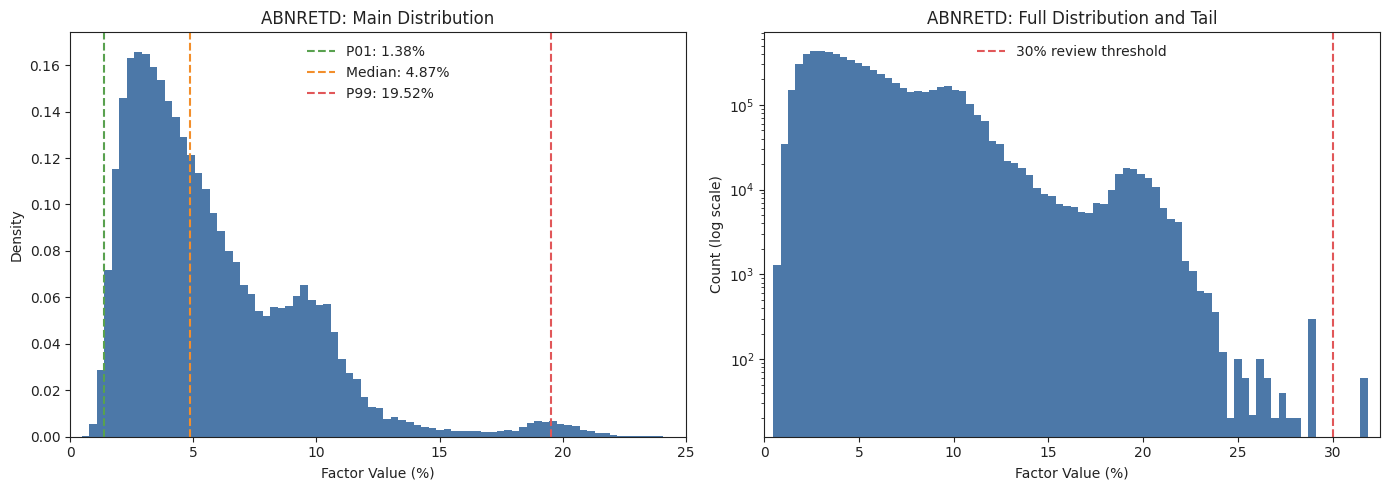

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# 提取有效因子值；0.05 表示 5%
values = (
    abnretd_panel["ABNRETD"]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

values_pct = values.values * 100
p01, p50, p99 = values.quantile([0.01, 0.50, 0.99]).values * 100

# 左图聚焦主体，右图保留完整尾部
main_upper = max(25.0, float(values.quantile(0.995) * 100))
full_upper = float(values.max() * 100)

plt.style.use("default")

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 主体分布
main_values = values_pct[values_pct <= main_upper]
axes[0].hist(main_values, bins=80, density=True, color="#4C78A8")
axes[0].axvline(p01, color="#59A14F", linestyle="--", label="P01: {:.2f}%".format(p01))
axes[0].axvline(p50, color="#F28E2B", linestyle="--", label="Median: {:.2f}%".format(p50))
axes[0].axvline(p99, color="#E15759", linestyle="--", label="P99: {:.2f}%".format(p99))
axes[0].set_xlim(0, main_upper)
axes[0].set_title("ABNRETD: Main Distribution")
axes[0].set_xlabel("Factor Value (%)")
axes[0].set_ylabel("Density")
axes[0].legend(frameon=False)

# 全样本与尾部
axes[1].hist(values_pct, bins=80, color="#4C78A8")
axes[1].axvline(30, color="#E15759", linestyle="--", label="30% review threshold")
axes[1].set_yscale("log")
axes[1].set_xlim(0, full_upper * 1.02)
axes[1].set_title("ABNRETD: Full Distribution and Tail")
axes[1].set_xlabel("Factor Value (%)")
axes[1].set_ylabel("Count (log scale)")
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

for ax in axes:
    ax.grid(alpha=0.25)
    ax.set_axisbelow(True)

# 平均异常日收益率（ABNRETAVG）

**行为金融因子 —— 投资者注意力**

$$
\text{ABNRETAVG} = \frac{1}{m} \sum_{t}^{t-m+1} \left( r_{i,t} - \bar{r}_t \right)^2
$$

其中：

* $r_{i,t}$ 为股票 $i$ 在交易日 $t$ 的收益率；
* $\bar{r}_t$ 为交易日 $t$ 的全市场收益率；
* $m$ 为交易日窗口，一般取为月度。

## 因子说明

平均异常日收益率（ABNRETAVG）为每月日频收益率与市场收益率差值的均方，属于**极端日收益类因子**。极端收益（无论是大幅上涨还是大幅下跌）的股票，相比收益平稳的股票更能吸引投资者的关注。因子取值越高，表明该股票在当月曾出现过较为极端的日收益偏离，投资者的关注度也就越高。

然而，**投资者的注意力是有限的，他们更倾向于交易那些引起自己注意的股票。通常情况下，关注度较高的股票会伴随更多的买入行为**。但在 A 股市场中，由于**做多与做空机制不对称**，投资者非理性买入的倾向强于非理性卖出，导致高关注度股票因净买入力量而出现短期价格溢价，这种过度反应往往会在未来引发价格反转。

数据：日度收盘价

In [19]:
def calculate_abnretavg_daily(
    start_date,
    end_date,
    window=20,
    candidate_ids=None,
    market_ids=None,
    batch_size=500,
    min_market_stocks=500,
):
    """
    计算日频滚动平均异常日收益率（ABNRETAVG）。

    ABNRETAVG_i,T =
        mean_{t=T-window+1,...,T}[(r_i,t - r_bar,t)^2]

    返回
    ----
    DataFrame
        MultiIndex：date、order_book_id
        Column：ABNRETAVG
    """
    target_dates, price_dates = _prepare_dates(
        start_date=start_date,
        end_date=end_date,
        lookback_days=window,
    )

    market_ids = _get_ids(market_ids)
    candidate_ids = _get_ids(candidate_ids)

    return_dates = price_dates[1:]

    # 第一遍：计算全市场每日等权平均收益 r_bar,t。
    return_sum = pd.Series(0.0, index=return_dates)
    return_count = pd.Series(0, index=return_dates, dtype="int64")

    for start in range(0, len(market_ids), batch_size):
        batch = market_ids[start:start + batch_size]

        close, volume = _get_batch_close_volume(batch, price_dates)
        if close is None:
            continue

        returns = _get_returns(close, volume)

        return_sum += returns.sum(axis=1, skipna=True)
        return_count += returns.notna().sum(axis=1).astype("int64")

    market_returns = (
        return_sum / return_count.replace(0, np.nan)
    ).where(return_count >= min_market_stocks)

    # 第二遍：计算每只股票的滚动平均异常收益平方。
    factor_parts = []

    for start in range(0, len(candidate_ids), batch_size):
        batch = candidate_ids[start:start + batch_size]

        close, volume = _get_batch_close_volume(batch, price_dates)
        if close is None:
            continue

        returns = _get_returns(close, volume)

        abnormal_return_squared = (
            returns.sub(market_returns, axis=0)
            .pow(2)
        )

        # 每日以过去 window 个交易日为窗口。
        factor_wide = abnormal_return_squared.rolling(
            window=window,
            min_periods=window,
        ).mean()

        factor_wide = factor_wide.reindex(target_dates)
        factor_parts.append(
            _stack_factor(factor_wide, "ABNRETAVG")
        )

    if not factor_parts:
        return pd.DataFrame(columns=["ABNRETAVG"])

    return pd.concat(factor_parts).sort_index()

def exclude_recent_listings(abnretavg_panel, min_trading_days=60):
    """剔除上市未满指定交易日的股票因子值。

    以股票上市日为第 0 个交易日；当其后的 ``min_trading_days`` 个交易日均已
    过去，才保留因子。例如 ``min_trading_days=60`` 时，上市后的第 61 个交易日
    起才允许使用 ABNRETAVG。该规则可避免新股上市初期的无涨跌幅限制波动主导排序。

    本函数只过滤最终因子面板；因此可以直接接在
    ``calculate_abnretavg_daily(...)`` 后使用。
    """
    if min_trading_days < 0:
        raise ValueError("min_trading_days 不能为负数。")
    if not isinstance(abnretavg_panel.index, pd.MultiIndex) or abnretavg_panel.index.nlevels != 2:
        raise ValueError("索引必须为两层 MultiIndex：(date, order_book_id)。")

    # 延迟导入，使单纯的数据检查不依赖已初始化的 rqdatac。
    from rqdatac import all_instruments, get_trading_dates

    panel = abnretavg_panel.copy()
    panel.index = panel.index.set_names(["date", "order_book_id"])
    signal_dates = pd.DatetimeIndex(panel.index.get_level_values("date"))
    stock_ids = pd.Index(panel.index.get_level_values("order_book_id").unique())

    instruments_df = all_instruments("CS").set_index("order_book_id")
    listed_dates = pd.to_datetime(
        instruments_df["listed_date"].reindex(stock_ids), errors="coerce"
    )
    if listed_dates.isna().any():
        missing_ids = listed_dates[listed_dates.isna()].index.tolist()[:10]
        raise ValueError("以下股票缺少 listed_date：{}".format(missing_ids))

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=listed_dates.min(),
            end_date=signal_dates.max(),
        )
    )
    listing_locs = calendar.searchsorted(listed_dates.to_numpy(), side="left")
    eligible_locs = listing_locs + min_trading_days

    eligible_from_values = np.full(
        len(stock_ids), np.datetime64("NaT"), dtype="datetime64[ns]"
    )
    within_calendar = eligible_locs < len(calendar)
    eligible_from_values[within_calendar] = calendar.to_numpy()[eligible_locs[within_calendar]]
    eligible_from = pd.Series(pd.to_datetime(eligible_from_values), index=stock_ids)

    row_ids = panel.index.get_level_values("order_book_id")
    row_eligible_from = eligible_from.reindex(row_ids).to_numpy()
    keep = signal_dates.to_numpy() >= row_eligible_from
    return panel.loc[keep].sort_index()

In [20]:
abnretavg_panel = calculate_abnretavg_daily(
    start_date="2020-01-01",
    end_date="2025-12-31",
    window=20,
)

# 上市后的第 61 个交易日起才保留因子
abnretavg_panel = exclude_recent_listings(
    abnretavg_panel,
    min_trading_days=60,
)

abnretavg_panel.head()

ABNRETAVG
date       order_book_id           
2020-01-02 000001.XSHE     0.000130
           000002.XSHE     0.000258
           000004.XSHE     0.000686
           000005.XSHE     0.000073
           000006.XSHE     0.000073

> WARNING: 现在过滤的是最终的个股因子值；新股上市初期的极端收益仍可能参与当日全市场收益 r_bar,t 的计算。不过全市场有数千只股票，单只新股对等权市场收益的影响通常很小。若你希望执行最严格的口径，则还应让上市未满 60 日的股票不参与 market_returns 的计算。当前版本用于因子输出与检验已经是合理的。

,数值,判断
指标,,
目标交易日数,1.455000e+03,
有至少一个因子值的交易日数,1.455000e+03,应接近目标交易日数
完全无输出交易日数,0.000000e+00,应为 0
实际有效观测数,6.691929e+06,
覆盖股票数,5.361000e+03,
重复 date-stock,0.000000e+00,应为 0
显式缺失值,0.000000e+00,最终 stack 后通常应为 0
无穷值（inf/-inf）,0.000000e+00,应为 0
负值,0.000000e+00,应为 0：收益平方均值不应为负



最近 5 个交易日的横截面统计（单位：RMS 异常日收益率 %）


,因子股票数,均值,标准差,最小值,中位数,最大值,P01,P05,P95,P99,年份,相对覆盖率
date,,,,,,,,,,,,
2025-12-25,5085,2.062864,1.290081,0.399027,1.663946,9.642262,0.616227,0.772289,4.773347,6.697734,2025,0.994913
2025-12-26,5084,2.068121,1.294112,0.434515,1.666613,9.583366,0.626205,0.768815,4.799982,6.554107,2025,0.994717
2025-12-29,5085,2.075398,1.311774,0.460454,1.665975,10.119312,0.622790,0.765277,4.846141,6.756041,2025,0.994913
2025-12-30,5087,2.089750,1.324083,0.453234,1.679200,10.776999,0.619826,0.764248,4.895785,6.690642,2025,0.995304
2025-12-31,5092,2.092724,1.330249,0.445386,1.673808,10.072351,0.620392,0.759483,4.863849,6.690015,2025,0.996283



因子值最大的 20 条记录：


,date,order_book_id,ABNRETAVG,rms_abnormal_return_pct
4783992,2024-06-18,300262.XSHE,0.022577,15.025646
2042148,2022-02-14,300584.XSHE,0.021224,14.568478
2037641,2022-02-11,300584.XSHE,0.021183,14.554506
2028637,2022-02-09,300584.XSHE,0.020945,14.472447
2033137,2022-02-10,300584.XSHE,0.020883,14.451081
5208352,2024-10-23,300085.XSHE,0.020511,14.321831
4778941,2024-06-17,300262.XSHE,0.020313,14.252235
5203298,2024-10-22,300085.XSHE,0.020297,14.246687
5198243,2024-10-21,300085.XSHE,0.020109,14.180648
5193187,2024-10-18,300085.XSHE,0.020073,14.167974


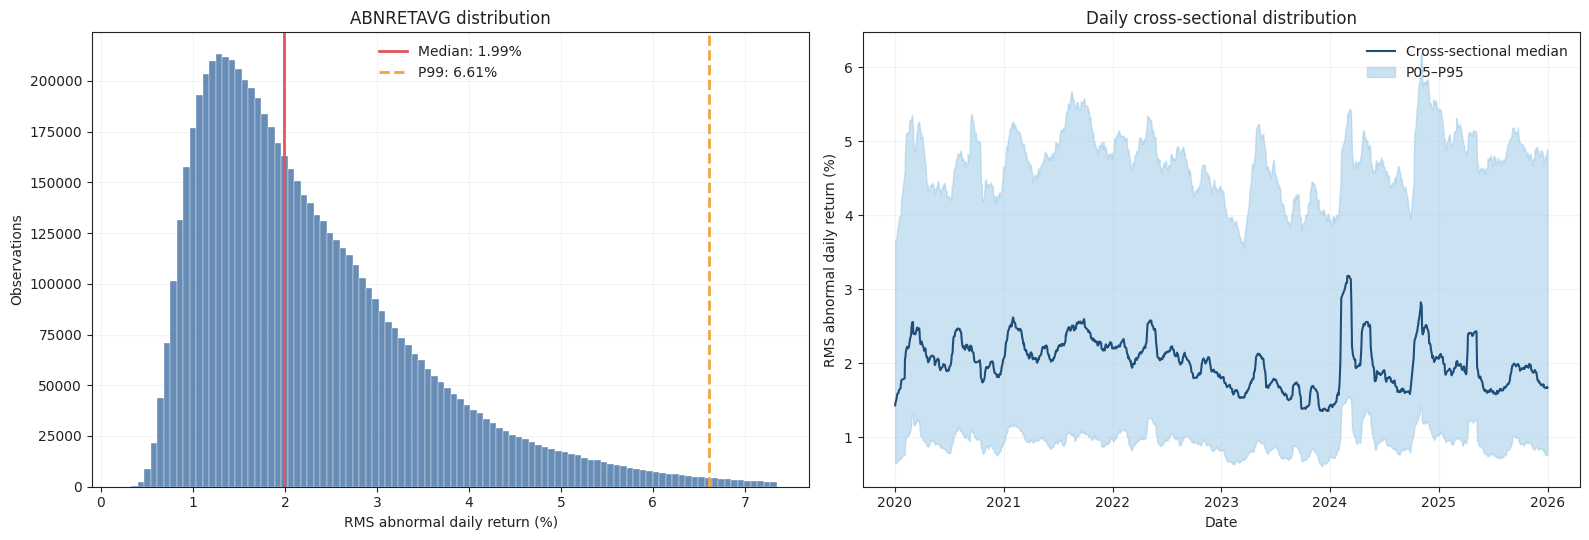

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from rqdatac import get_trading_dates

FACTOR_NAME = "ABNRETAVG"
START_DATE = "2020-01-01"
END_DATE = "2025-12-31"

# 若你尚未对 ABNRETAVG 应用“上市满 60 个交易日”过滤，
# 请先使用与 ABNRETD 相同的过滤规则，再执行本检查代码。

panel = abnretavg_panel.copy()

# ---------- 1. 基础结构检查 ----------
if not isinstance(panel.index, pd.MultiIndex):
    raise ValueError("abnretavg_panel 应为 date、order_book_id 两层 MultiIndex。")

if FACTOR_NAME not in panel.columns:
    raise ValueError("未找到因子列：{}".format(FACTOR_NAME))

if "date" not in panel.index.names or "order_book_id" not in panel.index.names:
    raise ValueError("MultiIndex 名称应为 date、order_book_id。")

check_data = pd.DataFrame({
    "date": pd.to_datetime(panel.index.get_level_values("date")),
    "order_book_id": panel.index.get_level_values("order_book_id"),
    FACTOR_NAME: pd.to_numeric(panel[FACTOR_NAME], errors="coerce").values,
})

expected_dates = pd.DatetimeIndex(
    pd.to_datetime(
        get_trading_dates(
            start_date=START_DATE,
            end_date=END_DATE,
        )
    )
)

raw_value = check_data[FACTOR_NAME]
is_finite = np.isfinite(raw_value)
is_nonnegative = raw_value >= 0
is_valid = is_finite & is_nonnegative

valid = check_data.loc[is_valid].copy()

# 将“收益率平方”转换为更容易理解的 RMS 异常日收益率（%）
valid["rms_abnormal_return_pct"] = np.sqrt(valid[FACTOR_NAME]) * 100

# ---------- 2. 每日覆盖与横截面统计 ----------
daily = valid.groupby("date")["rms_abnormal_return_pct"].agg(
    ["count", "mean", "std", "min", "median", "max"]
)
daily.columns = ["因子股票数", "均值", "标准差", "最小值", "中位数", "最大值"]

daily["P01"] = valid.groupby("date")["rms_abnormal_return_pct"].quantile(0.01)
daily["P05"] = valid.groupby("date")["rms_abnormal_return_pct"].quantile(0.05)
daily["P95"] = valid.groupby("date")["rms_abnormal_return_pct"].quantile(0.95)
daily["P99"] = valid.groupby("date")["rms_abnormal_return_pct"].quantile(0.99)

daily = daily.reindex(expected_dates)
daily.index.name = "date"
daily["因子股票数"] = daily["因子股票数"].fillna(0)

# 每年以该年最大日覆盖股票数作为相对覆盖率基准
daily["年份"] = daily.index.year
year_max_count = daily.groupby("年份")["因子股票数"].transform("max")
daily["相对覆盖率"] = daily["因子股票数"] / year_max_count.replace(0, np.nan)

stock_days = valid.groupby("order_book_id").size()

# ---------- 3. 总体统计 ----------
rms = valid["rms_abnormal_return_pct"]

summary = pd.DataFrame([
    ["目标交易日数", len(expected_dates), ""],
    ["有至少一个因子值的交易日数", int((daily["因子股票数"] > 0).sum()),
     "应接近目标交易日数"],
    ["完全无输出交易日数", int((daily["因子股票数"] == 0).sum()),
     "应为 0"],
    ["实际有效观测数", len(valid), ""],
    ["覆盖股票数", valid["order_book_id"].nunique(), ""],
    ["重复 date-stock", int(check_data.duplicated(["date", "order_book_id"]).sum()),
     "应为 0"],
    ["显式缺失值", int(raw_value.isna().sum()),
     "最终 stack 后通常应为 0"],
    ["无穷值（inf/-inf）", int(np.isinf(raw_value).sum()),
     "应为 0"],
    ["负值", int((raw_value < 0).sum()),
     "应为 0：收益平方均值不应为负"],
    ["每日因子股票数均值", daily["因子股票数"].mean(), ""],
    ["每日因子股票数 P05", daily["因子股票数"].quantile(0.05),
     "检查低覆盖交易日"],
    ["相对覆盖率 P05", daily["相对覆盖率"].quantile(0.05),
     "建议大于 0.80"],
    ["单股有效天数 P05", stock_days.quantile(0.05),
     "新股、停牌股或退市股通常较低"],
    ["因子均值（收益率平方）", valid[FACTOR_NAME].mean(),
     "原始单位为收益率平方"],
    ["因子标准差（收益率平方）", valid[FACTOR_NAME].std(), ""],
    ["因子最小值", valid[FACTOR_NAME].min(),
     "应大于等于 0"],
    ["因子中位数", valid[FACTOR_NAME].median(), ""],
    ["因子 P99", valid[FACTOR_NAME].quantile(0.99), ""],
    ["因子最大值", valid[FACTOR_NAME].max(),
     "需结合 RMS 异常收益率复核"],
    ["RMS 异常日收益率均值（%）", rms.mean(),
     "更直观的经济含义"],
    ["RMS 异常日收益率中位数（%）", rms.median(), ""],
    ["RMS 异常日收益率 P99（%）", rms.quantile(0.99),
     "检查高波动股票"],
    ["RMS 异常日收益率最大值（%）", rms.max(),
     "过高时核对新股、复牌、拆并股或价格数据"],
    ["RMS 异常日收益率 > 15% 的观测数", int((rms > 15).sum()),
     "人工复核阈值，不自动代表错误"],
], columns=["指标", "数值", "判断"])

display(summary.set_index("指标"))

print("\n最近 5 个交易日的横截面统计（单位：RMS 异常日收益率 %）")
display(daily.tail())

print("\n因子值最大的 20 条记录：")
top20 = valid.sort_values(FACTOR_NAME, ascending=False).head(20)
display(
    top20[
        ["date", "order_book_id", FACTOR_NAME, "rms_abnormal_return_pct"]
    ]
)

# ---------- 4. 分布图 ----------
plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
    "axes.unicode_minus": False,
})

# 左图为避免极少数极端值压缩主体分布，仅显示至 P99.5
display_upper = rms.quantile(0.995)
rms_for_hist = rms[rms <= display_upper]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

axes[0].hist(
    rms_for_hist,
    bins=100,
    color="#4C78A8",
    alpha=0.85,
    edgecolor="white",
    linewidth=0.3,
)
axes[0].axvline(
    rms.median(),
    color="#E15759",
    linewidth=2,
    label="Median: {:.2f}%".format(rms.median()),
)
axes[0].axvline(
    rms.quantile(0.99),
    color="#F2A541",
    linewidth=2,
    linestyle="--",
    label="P99: {:.2f}%".format(rms.quantile(0.99)),
)
axes[0].set_title("ABNRETAVG distribution")
axes[0].set_xlabel("RMS abnormal daily return (%)")
axes[0].set_ylabel("Observations")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.25)
axes[0].set_axisbelow(True)

plot_daily = daily.dropna(subset=["中位数", "P05", "P95"]).copy()

axes[1].fill_between(
    plot_daily.index,
    plot_daily["P05"].values,
    plot_daily["P95"].values,
    color="#A0CBE8",
    alpha=0.55,
    label="P05–P95",
)
axes[1].plot(
    plot_daily.index,
    plot_daily["中位数"].values,
    color="#1F4E79",
    linewidth=1.5,
    label="Cross-sectional median",
)
axes[1].set_title("Daily cross-sectional distribution")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("RMS abnormal daily return (%)")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[1].legend(frameon=False)
axes[1].grid(alpha=0.25)
axes[1].set_axisbelow(True)

plt.tight_layout()
plt.show()

结论：**ABNRETAVG 的输出完整性与整体数值合理性均通过。** 没有发现结构性错误；但最大值对应的少数个股应做事件复核。

- 完整性很好：1,455 个交易日均有输出，重复、缺失、无穷值、负值均为 0。
- 覆盖率合格：相对覆盖率 P05 为 90.9%，说明低覆盖日也没有明显断层。
- 分布合理：原始因子非负且明显右偏，符合“异常收益平方均值”的数学特征；均值高于中位数是正常现象。
- 典型股票的日均方根异常收益率中位数为 **1.99%**，P99 为 **6.61%**；对全 A、包含高波动小盘股的样本而言合理。
- 2025 年末横截面中位数约 **1.66%–1.68%**、P99 约 **6.55%–6.76%**，与全样本分布一致，没有明显的尾期失真。

最大值 `0.022577` 对应 RMS 异常日收益率 **15.03%**。这不等于“平均每天涨跌 15%”，而是过去 20 日异常收益的均方根为 15%。如果只有单个 20% 异常日、其余日期接近零，RMS 仅约为：

$$
20\% / \sqrt{20} \approx 4.47\%
$$

因此 15% 意味着窗口内存在多日连续的大幅异常涨跌，或个别更大的复权/公司事件跳变。前二十条中 `300262.XSHE`、`300584.XSHE`、`300085.XSHE` 连续多日出现，正是滚动 20 日窗口保留同一段高波动行情的正常表现，不是重复记录。

这也是它与 ABNRETD 的关键差异：

- `ABNRETD`：捕捉一个月内**单日最大**异常。
- `ABNRETAVG`：捕捉一个月内异常收益的**整体强度与持续性**。

建议对最大的一条做一次价格与成交连续性复核；若确认为连续涨跌停、高波动行情或重大事件，则无需删除:

In [22]:
from rqdatac import get_price

stock_id = "300262.XSHE"
peak_date = "2024-06-18"

raw = get_price(
    order_book_ids=stock_id,
    start_date="2024-05-10",
    end_date=peak_date,
    frequency="1d",
    fields=["close", "volume"],
    adjust_type="pre",
    skip_suspended=False,
    expect_df=True,
)

if isinstance(raw.index, pd.MultiIndex):
    raw = raw.reset_index()
    raw["date"] = pd.to_datetime(raw["date"])
    raw = raw.set_index("date")
else:
    raw.index = pd.to_datetime(raw.index)

raw = raw.sort_index()
raw["daily_return"] = raw["close"].pct_change(fill_method=None)
raw["previous_volume"] = raw["volume"].shift(1)
raw["valid_return"] = raw["daily_return"].where(
    raw["volume"].gt(0)
    & raw["previous_volume"].gt(0)
    & raw["close"].gt(0)
    & raw["close"].shift(1).gt(0)
)

display(raw.sort_values("valid_return", key=lambda x: x.abs(), ascending=False))

,order_book_id,close,volume,daily_return,previous_volume,valid_return
date,,,,,,
2024-06-05,300262.XSHE,0.58,72379827.0,0.208333,76475387.0,0.208333
2024-06-06,300262.XSHE,0.70,69984222.0,0.206897,72379827.0,0.206897
2024-05-14,300262.XSHE,1.00,74346329.0,0.204819,57614336.0,0.204819
2024-06-14,300262.XSHE,0.71,99079686.0,-0.202247,77381554.0,-0.202247
2024-06-07,300262.XSHE,0.84,42007151.0,0.200000,69984222.0,0.200000
2024-06-18,300262.XSHE,0.68,133328258.0,-0.200000,115850736.0,-0.200000
2024-06-03,300262.XSHE,0.57,54956783.0,-0.197183,77543106.0,-0.197183
2024-06-17,300262.XSHE,0.85,115850736.0,0.197183,99079686.0,0.197183
2024-05-24,300262.XSHE,0.98,74644285.0,0.195122,51442816.0,0.195122


这条最大值确认是**真实的连续高波动行情，不是停牌复牌、新股首日或成交量缺失造成的数据错误**。

证据很明确：

- 每个异常日的 `volume > 0`，且 `previous_volume > 0`；
- 多日出现接近 ±20% 的日收益，符合创业板股票的涨跌幅约束；
- 2024-05-22 至 2024-06-18 的 20 日窗口中，存在多次约 ±20% 的涨跌，且成交量持续存在；
- 因而 `ABNRETAVG=0.022577`、RMS 异常日收益率约 15% 在数学上是成立的。

这正好解释了为什么它远高于 P99 的 6.61%：它不是由单日跳变驱动，而是由一段持续的剧烈上涨、下跌和反转共同驱动。`300262.XSHE` 在该窗口内属于极端注意力/高投机状态，符合因子的经济含义。

所以：

- 不需要删除该观测；
- 不需要修改收益率或上市 60 日过滤规则；
- 可以保留该因子的原始值用于研究。

若后续用于横截面选股或回测，建议在每个交易日截面内做轻度缩尾，例如 0.5%–99.5% 分位数缩尾。目的不是修正错误，而是避免少数持续涨跌停股票在组合排序或标准化时拥有过强影响。

In [23]:
# 行：交易日；列：order_book_id；值：ABNRETD
abnretavg_panel_df = (
    abnretavg_panel["ABNRETAVG"]
    .unstack("order_book_id")
    .sort_index()
)

abnretavg_panel_df.index = pd.to_datetime(abnretavg_panel_df.index)
abnretavg_panel_df.columns.name = "order_book_id"

abnretavg_panel_df

order_book_id,000001.XSHE,000002.XSHE,000004.XSHE,000005.XSHE,000006.XSHE,000007.XSHE,000008.XSHE,000009.XSHE,000010.XSHE,000011.XSHE,...,603406.XSHG,301632.XSHE,603370.XSHG,301575.XSHE,603418.XSHG,301584.XSHE,301656.XSHE,301668.XSHE,001285.XSHE,301563.XSHE
date,,,,,,,,,,,,,,,,,,,,,
2020-01-02,0.000130,0.000258,0.000686,0.000073,0.000073,0.000833,0.000237,0.001612,0.000196,0.000095,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,0.000138,0.000276,0.000684,0.000073,0.000074,0.000830,0.000210,0.001710,0.000111,0.000097,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-06,0.000147,0.000304,0.000734,0.000073,0.000080,0.000821,0.000177,0.002138,0.000090,0.000111,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-07,0.000138,0.000303,0.000675,0.000069,0.000083,0.000361,0.000086,0.002125,0.000096,0.000111,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-08,0.000144,0.000298,0.000665,0.000067,0.000080,0.000355,0.000087,0.002082,0.000090,0.000116,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-25,0.000125,0.000921,0.000695,NaN,0.000344,0.001546,0.000099,0.000081,0.000286,0.000160,...,0.000149,0.000158,0.000136,0.000454,0.000160,NaN,NaN,NaN,NaN,NaN
2025-12-26,0.000104,0.000881,0.000624,NaN,0.000337,0.001556,0.000089,0.000074,0.000304,0.000145,...,0.000148,0.000129,0.000118,0.000452,0.000160,0.000497,0.000255,NaN,NaN,NaN
2025-12-29,0.000104,0.000804,0.000527,NaN,0.000231,0.001114,0.000078,0.000087,0.000294,0.000105,...,0.000159,0.000118,0.000119,0.000451,0.000156,0.000498,0.000253,0.000279,NaN,NaN


In [25]:
from rqfactor.notebook import factor_analysis

result_abnretavg = factor_analysis(
    f=abnretavg_panel_df,
    period=1,
    shift=1,
    rank_ic=True,
    quantile=5,
    ascending=True,
    winzorization="mad",
    normalization=False,
    neutralization="none",   # 先关闭：这是日频测试最常见的慢点
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)

In [26]:
result_abnretavg.show()

Loading BokehJS ...

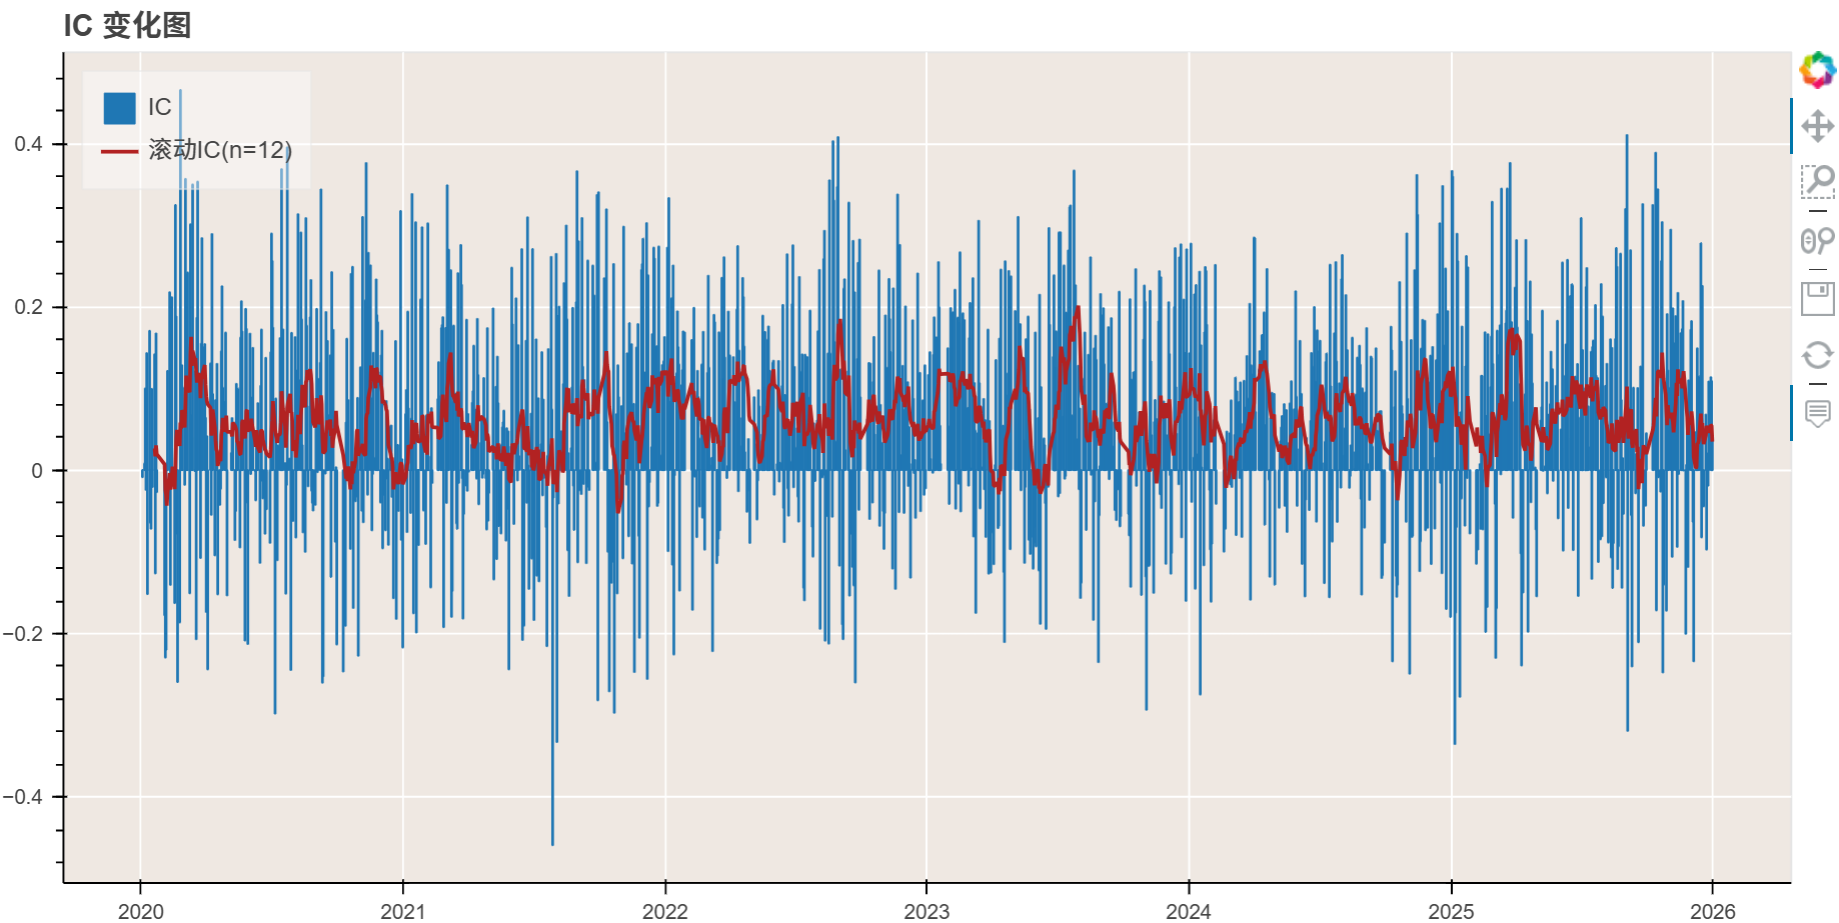

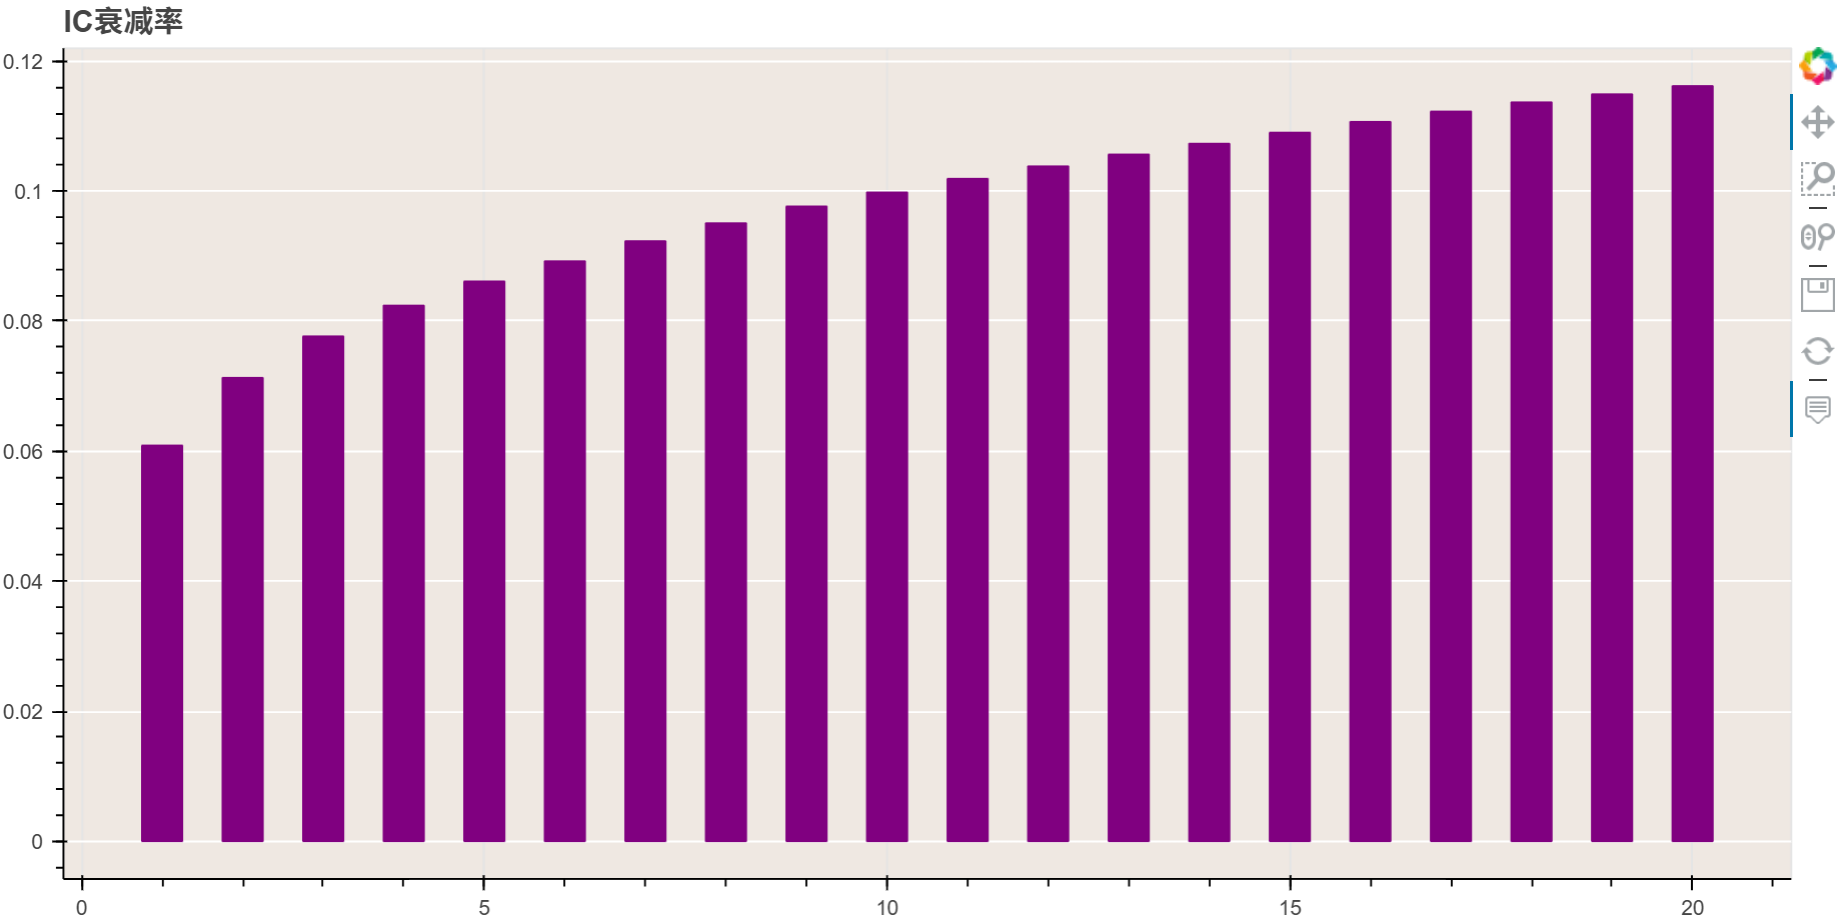

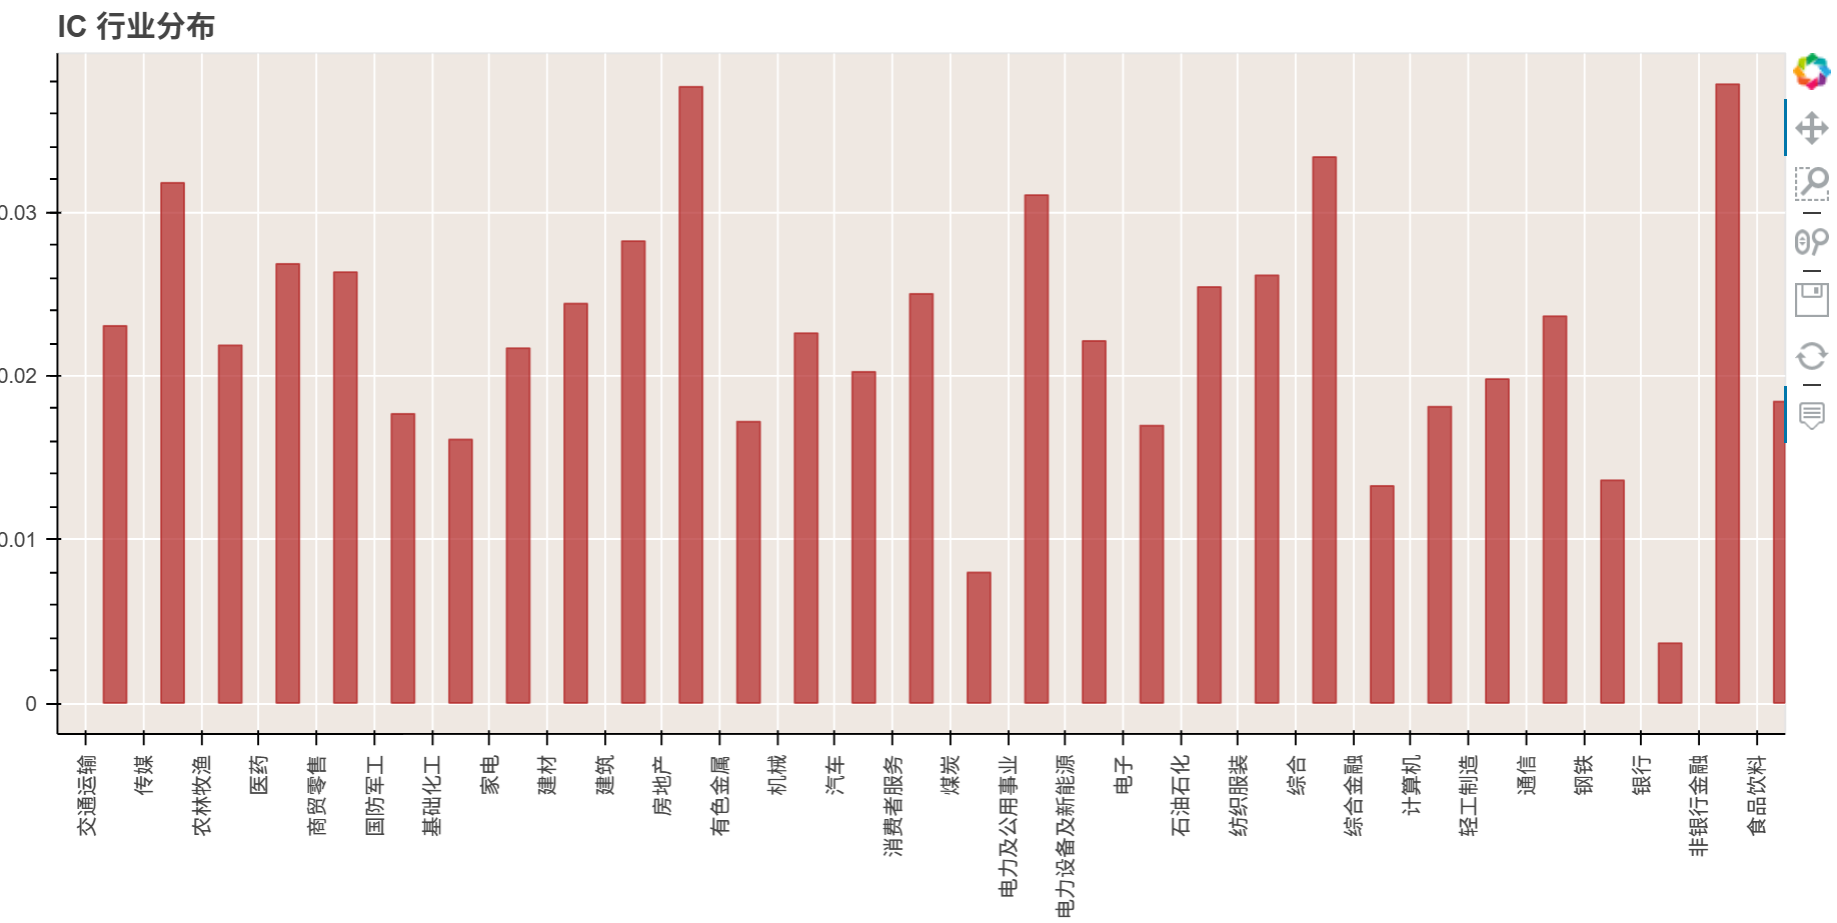

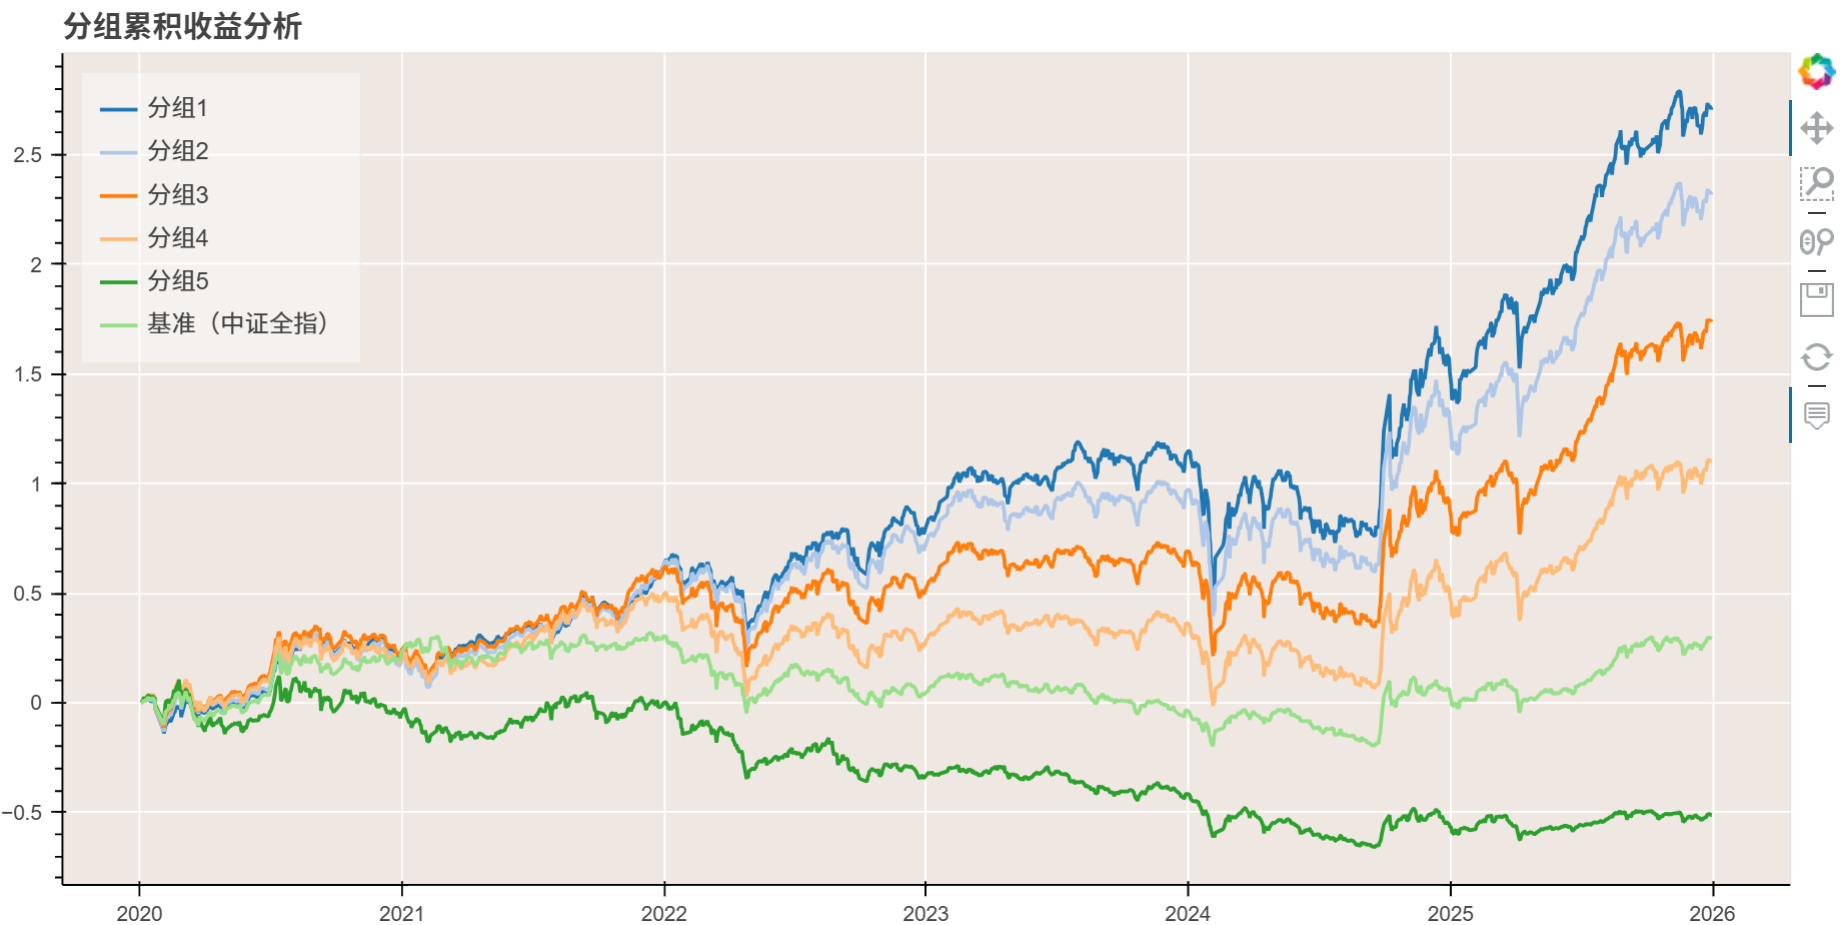

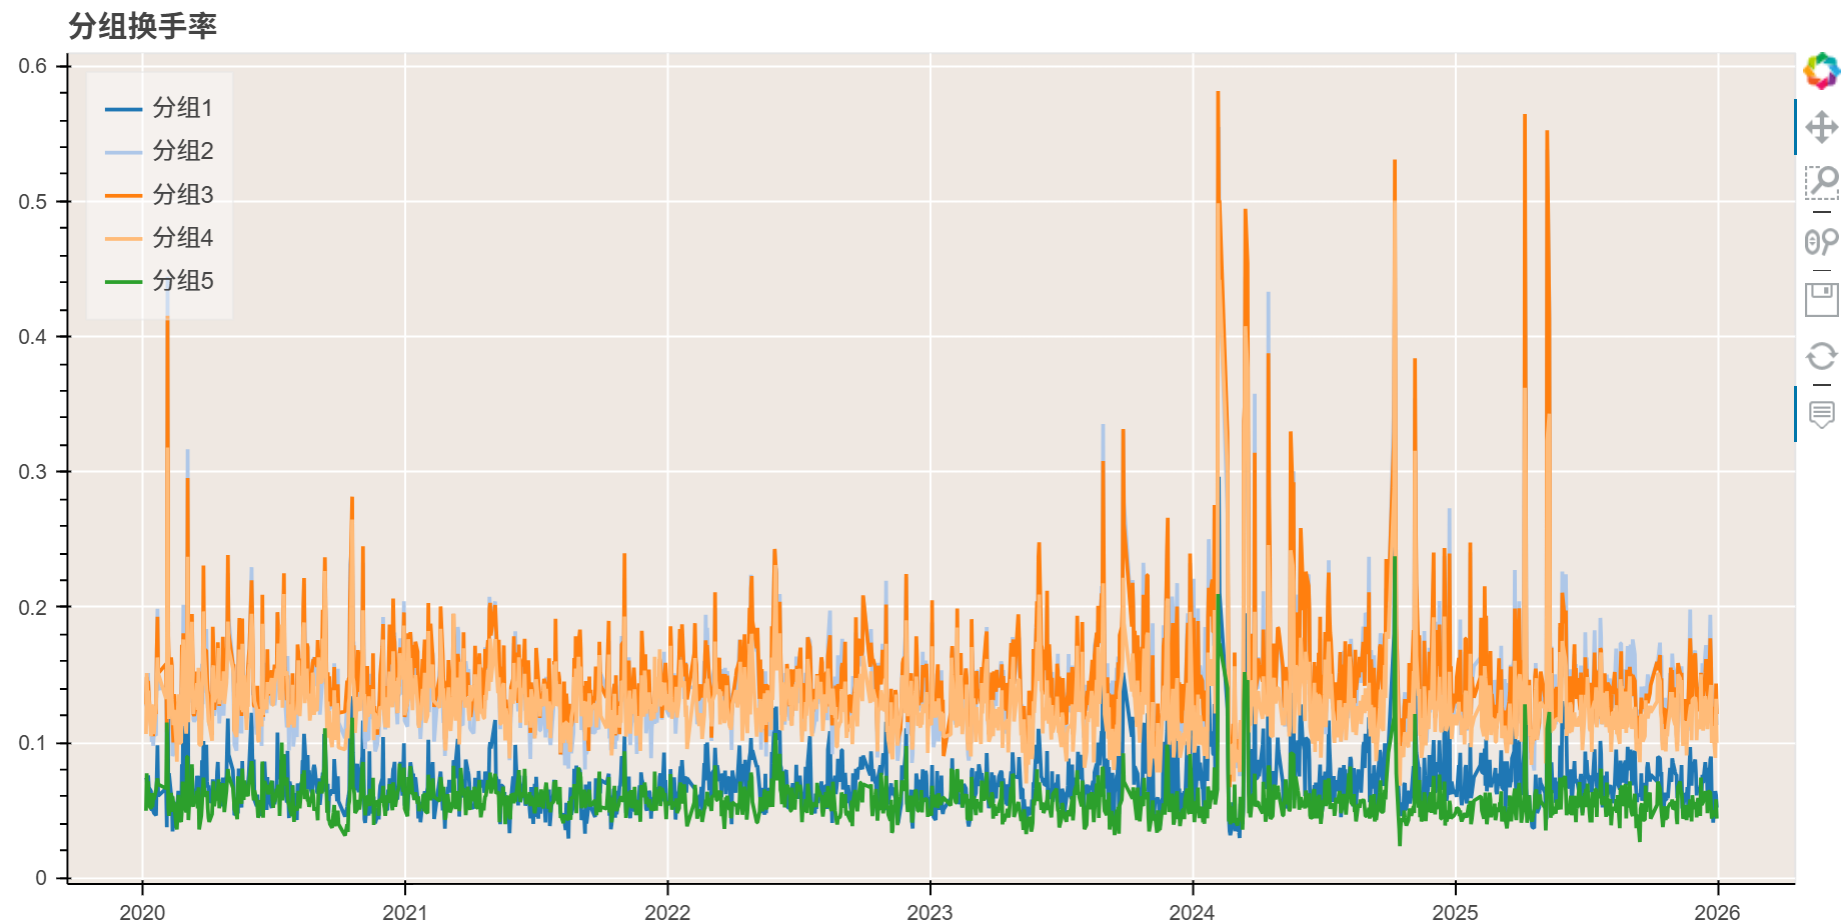

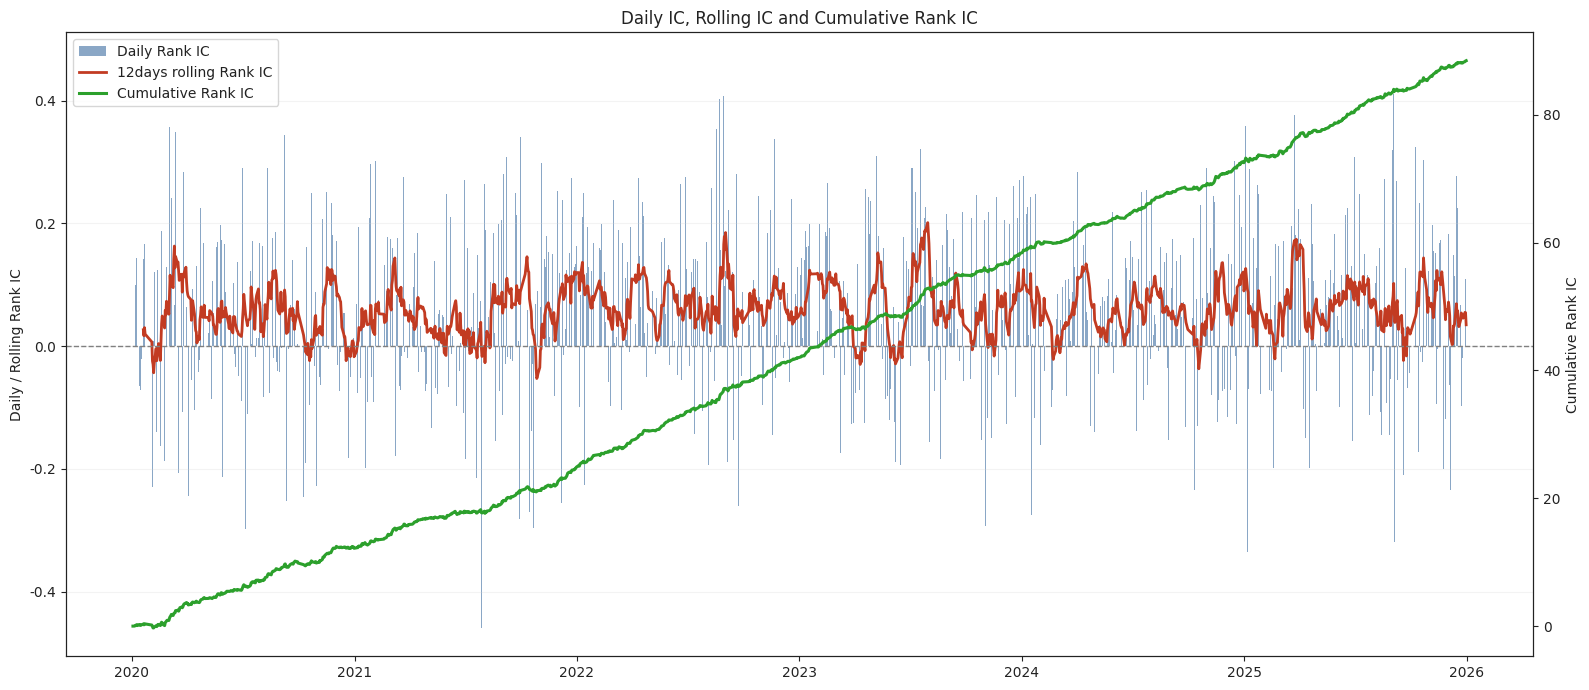

In [30]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result_abnretavg.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="Daily Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}days rolling Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("Daily / Rolling Rank IC")
ax1.set_title("Daily IC, Rolling IC and Cumulative Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="Cumulative Rank IC",
)

ax2.set_ylabel("Cumulative Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["Daily Rank IC", f"{rolling_window}days rolling Rank IC", "Cumulative Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()

ABNRETAVG 的回测表现很强，而且与 ABNRETD 呈现出几乎相同的结构：它们大概率不是两条独立 Alpha，而是同一类“异常波动 / 注意力 / 残差波动率”信号的两个版本。

先说结论：

- 分组收益高度单调。分组 1 期末约 `+270%`，分组 2 约 `+230%`，分组 3 约 `+170%`，分组 4 约 `+110%`，分组 5 约 `-50%`；中证全指约 `+25%`。
- IC 衰减并不明显，1 日 IC 约 `0.061`，20 日约 `0.116`。信号不只是隔日效应，预测关系会在后续数周积累。
- 行业 IC 几乎全为正，房地产、非银金融、综合、传媒等更强；银行接近零。这说明有效性不局限于一两个行业。
- 累计 Rank IC 持续向上、期末接近 `90`，中间虽有回撤但没有长时间失效区间。
- 分组 1、5 的日换手多在约 5%–8%；中间组更高，常在 10%–15%，且有尖峰。若最终只交易优组或构造首尾组合，交易成本压力相对可控，但仍需实际扣费验证。

但这张分组曲线与先前 ABNRETD 极其相似，不能直接把两者当作两个可简单相加的因子。原因在于你定义的 ABNRETAVG：

$$
\frac{1}{20}\sum(r_i-\bar r)^2
$$

本质上是过去 20 日的“市场调整后收益方差”，也就是一种异常波动率；而 ABNRETD 是同一窗口内异常波动的最大值。两者都在衡量异常日波动，只是：

- ABNRETD 更受单次极端涨跌影响；
- ABNRETAVG 更平滑，更代表持续性的异常波动。

从图上看，ABNRETAVG 的 1 日 IC 和 20 日 IC 都略高于你此前 ABNRETD 的图，但这不足以证明它更优，仍要直接比较两者的相关性及增量贡献。

建议马上做这个检查：

```python
f_max = abnretd_panel["ABNRETD"].unstack("order_book_id")
f_avg = abnretavg_panel["ABNRETAVG"].unstack("order_book_id")

common_dates = f_max.index.intersection(f_avg.index)
common_ids = f_max.columns.intersection(f_avg.columns)

f_max = f_max.loc[common_dates, common_ids]
f_avg = f_avg.loc[common_dates, common_ids]

# 每日横截面的秩相关：比原始 Pearson 更适合因子值比较
daily_rank_corr = pd.Series(
    {
        dt: f_max.loc[dt].corr(f_avg.loc[dt], method="spearman")
        for dt in common_dates
    }
)

print(daily_rank_corr.describe(percentiles=[0.1, 0.5, 0.9]))

# 两个因子“预测效果”本身是否同步
print(
    "IC 序列相关性：",
    result_abnretd.ic.corr(result_abnretavg.ic)
)
```

判断标准很简单：

- 每日秩相关长期大于 `0.8`：二者高度重复，二选一即可；
- 在 `0.5–0.8`：同一因子族，但可能有组合价值；
- 小于 `0.5`：才值得进一步做双因子组合。

下一步最关键的是风格剥离。ABNRETAVG 很容易被误认为注意力 Alpha，但它也可能只是捕捉到小市值、高波动、低流动性或高残差波动股票。建议优先验证：

1. 行业中性化后，分组收益是否仍单调；
2. 在大盘、中盘、小盘内分别测试；
3. 控制市值、流动性与残差波动率后，IC 是否仍显著；
4. 用 RQAlpha Plus 按 T+1 开盘成交、加入涨跌停/停牌/佣金/滑点，测试成本后夏普。

目前可以把它定位为：**非常强的候选异常波动因子，但尚未证明其相对于 ABNRETD 具有独立增量，也尚未证明收益不是风险风格暴露或交易不可实现性带来的。**

In [28]:
f_max = abnretd_panel["ABNRETD"].unstack("order_book_id")
f_avg = abnretavg_panel["ABNRETAVG"].unstack("order_book_id")

common_dates = f_max.index.intersection(f_avg.index)
common_ids = f_max.columns.intersection(f_avg.columns)

f_max = f_max.loc[common_dates, common_ids]
f_avg = f_avg.loc[common_dates, common_ids]

# 每日横截面的秩相关：比原始 Pearson 更适合因子值比较
daily_rank_corr = pd.Series(
    {
        dt: f_max.loc[dt].corr(f_avg.loc[dt], method="spearman")
        for dt in common_dates
    }
)

print(daily_rank_corr.describe(percentiles=[0.1, 0.5, 0.9]))

# 两个因子“预测效果”本身是否同步
print(
    "IC 序列相关性：",
    result_abnretd.ic.corr(result_abnretavg.ic)
)

count    1455.000000
mean        0.943433
std         0.010670
min         0.895520
10%         0.930205
50%         0.944436
90%         0.955394
max         0.962248
dtype: float64
IC 序列相关性： 0.9926662616816726
